In [ ]:
# Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

# Import libraries
import pandas as pd
import numpy as np
import os

# Load the cleaned dataset
DATA_PATH = "/content/drive/MyDrive/shared iot/processed_data/cleaned_dataset.csv"

df = pd.read_csv(DATA_PATH)

print("Dataset shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

# Inspect all original attack labels
print("\nUnique Attack_Type labels:")
attack_labels = sorted(df["Attack_Type"].dropna().unique())

for label in attack_labels:
    print(label)

print("\nTotal unique attack labels:", len(attack_labels))

Mounted at /content/drive
Dataset shape: (730242, 41)

Columns:
['Header_Length', 'Protocol Type', 'Time_To_Live', 'Rate', 'fin_flag_number', 'syn_flag_number', 'rst_flag_number', 'psh_flag_number', 'ack_flag_number', 'ece_flag_number', 'cwr_flag_number', 'ack_count', 'syn_count', 'fin_count', 'rst_count', 'HTTP', 'HTTPS', 'DNS', 'Telnet', 'SMTP', 'SSH', 'IRC', 'TCP', 'UDP', 'DHCP', 'ARP', 'ICMP', 'IGMP', 'IPv', 'LLC', 'Tot sum', 'Min', 'Max', 'AVG', 'Std', 'Tot size', 'IAT', 'Number', 'Variance', 'Attack_Type', 'Binary_Label']

Unique Attack_Type labels:
Backdoor_Malware
Benign_Final
BrowserHijacking
CommandInjection
DDoS-ACK_Fragmentation
DDoS-HTTP_Flood
DDoS-ICMP_Flood
DDoS-ICMP_Fragmentation
DDoS-PSHACK_FLOOD
DDoS-RSTFINFLOOD
DDoS-SYN_Flood
DDoS-SlowLoris
DDoS-SynonymousIP_Flood
DDoS-TCP_Flood
DDoS-UDP_Flood
DDoS-UDP_Fragmentation
DNS_Spoofing
DictionaryBruteForce
DoS-HTTP_Flood
DoS-SYN_Flood
DoS-TCP_Flood
DoS-UDP_Flood
MITM-ArpSpoofing
Mirai-greeth_flood
Mirai-greip_flood
Mirai-ud

In [ ]:
# Separate input features and target labels
feature_columns = [
    col for col in df.columns
    if col not in ["Attack_Type", "Binary_Label"]
]

X = df[feature_columns].copy()
y = df["Attack_Type"].copy()

print("Feature shape:", X.shape)
print("Target shape:", y.shape)

print("\nClass distribution:")
print(y.value_counts())

Feature shape: (730242, 39)
Target shape: (730242,)

Class distribution:
Attack_Type
DDoS-ICMP_Flood            88293
DDoS-UDP_Flood             76905
DDoS-PSHACK_FLOOD          64081
DDoS-SYN_Flood             64003
DDoS-TCP_Flood             62519
DDoS-RSTFINFLOOD           57578
DoS-UDP_Flood              54287
DDoS-SynonymousIP_Flood    53308
DoS-TCP_Flood              42933
DoS-SYN_Flood              36563
Benign_Final               23455
Mirai-greeth_flood         21161
Mirai-udpplain             18942
Mirai-greip_flood          16039
DDoS-ICMP_Fragmentation     9672
VulnerabilityScan           7979
MITM-ArpSpoofing            6266
DDoS-UDP_Fragmentation      6133
DDoS-ACK_Fragmentation      6093
DNS_Spoofing                3799
Recon-HostDiscovery         2872
Recon-OSScan                2097
Recon-PortScan              1756
DoS-HTTP_Flood              1535
DDoS-HTTP_Flood              615
DDoS-SlowLoris               501
DictionaryBruteForce         279
BrowserHijacking        

In [ ]:
# Generate a hash for each feature row
feature_hash_34 = pd.util.hash_pandas_object(X, index=False)

# Associate each feature hash with its attack label
hash_labels_34 = pd.DataFrame({
    "Feature_Hash": feature_hash_34,
    "Attack_Type": y
})

# Find feature groups containing multiple attack labels
labels_per_group_34 = (
    hash_labels_34.groupby("Feature_Hash")["Attack_Type"].nunique()
)

conflicting_groups_34 = labels_per_group_34[
    labels_per_group_34 > 1
].index

# Identify all rows belonging to conflicting groups
conflicting_mask_34 = feature_hash_34.isin(conflicting_groups_34)

# Remove all rows belonging to conflicting groups
df_34class = df.loc[~conflicting_mask_34].copy()

# Recreate features and target
X_34 = df_34class[feature_columns].copy()
y_34 = df_34class["Attack_Type"].copy()

print("Total conflicting feature groups:", len(conflicting_groups_34))
print("Total conflicting rows:", conflicting_mask_34.sum())

print("\nDataset after conflict removal:", df_34class.shape)
print("Feature shape:", X_34.shape)
print("Target shape:", y_34.shape)

print("\nClass distribution after conflict removal:")
print(y_34.value_counts())

Total conflicting feature groups: 32119
Total conflicting rows: 68540

Dataset after conflict removal: (661702, 41)
Feature shape: (661702, 39)
Target shape: (661702,)

Class distribution after conflict removal:
Attack_Type
DDoS-ICMP_Flood            88293
DDoS-UDP_Flood             69679
DDoS-PSHACK_FLOOD          64081
DDoS-RSTFINFLOOD           57578
DDoS-TCP_Flood             52478
DDoS-SYN_Flood             50840
DoS-UDP_Flood              47061
DDoS-SynonymousIP_Flood    40864
DoS-TCP_Flood              32892
DoS-SYN_Flood              28276
Benign_Final               23430
Mirai-greeth_flood         21161
Mirai-udpplain             18942
Mirai-greip_flood          16039
DDoS-ICMP_Fragmentation     9672
VulnerabilityScan           7976
MITM-ArpSpoofing            6220
DDoS-UDP_Fragmentation      6133
DDoS-ACK_Fragmentation      6093
DNS_Spoofing                3787
Recon-HostDiscovery         2859
Recon-OSScan                2093
Recon-PortScan              1751
DoS-HTTP_Flood   

In [ ]:
from sklearn.model_selection import StratifiedGroupKFold

# Generate groups using identical feature rows
groups_34 = pd.util.hash_pandas_object(X_34, index=False)

# Create stratified group split
sgkf_34 = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

train_idx_34, test_idx_34 = next(
    sgkf_34.split(X_34, y_34, groups=groups_34)
)

# Split features and labels
X_train_34 = X_34.iloc[train_idx_34].copy()
X_test_34 = X_34.iloc[test_idx_34].copy()

y_train_34 = y_34.iloc[train_idx_34].copy()
y_test_34 = y_34.iloc[test_idx_34].copy()

# Check for group overlap
train_groups_34 = set(groups_34.iloc[train_idx_34])
test_groups_34 = set(groups_34.iloc[test_idx_34])

print("Training features:", X_train_34.shape)
print("Testing features:", X_test_34.shape)

print("\nTraining labels:", y_train_34.shape)
print("Testing labels:", y_test_34.shape)

print("\nTraining class distribution:")
print(y_train_34.value_counts())

print("\nTesting class distribution:")
print(y_test_34.value_counts())

print("\nGroup overlap:", len(train_groups_34.intersection(test_groups_34)))
print("Classes in training:", y_train_34.nunique())
print("Classes in testing:", y_test_34.nunique())

Training features: (529362, 39)
Testing features: (132340, 39)

Training labels: (529362,)
Testing labels: (132340,)

Training class distribution:
Attack_Type
DDoS-ICMP_Flood            70638
DDoS-UDP_Flood             55728
DDoS-PSHACK_FLOOD          51226
DDoS-RSTFINFLOOD           46047
DDoS-TCP_Flood             41985
DDoS-SYN_Flood             40760
DoS-UDP_Flood              37631
DDoS-SynonymousIP_Flood    32706
DoS-TCP_Flood              26318
DoS-SYN_Flood              22629
Benign_Final               18750
Mirai-greeth_flood         16887
Mirai-udpplain             15188
Mirai-greip_flood          12880
DDoS-ICMP_Fragmentation     7764
VulnerabilityScan           6344
MITM-ArpSpoofing            4952
DDoS-UDP_Fragmentation      4846
DDoS-ACK_Fragmentation      4837
DNS_Spoofing                3051
Recon-HostDiscovery         2299
Recon-OSScan                1681
Recon-PortScan              1406
DoS-HTTP_Flood              1211
DDoS-HTTP_Flood              507
DDoS-SlowLoris  

In [ ]:
from sklearn.preprocessing import StandardScaler

scaler_34 = StandardScaler()

X_train_34_scaled = scaler_34.fit_transform(X_train_34)
X_test_34_scaled = scaler_34.transform(X_test_34)

print("Training data shape:", X_train_34_scaled.shape)
print("Testing data shape:", X_test_34_scaled.shape)

Training data shape: (529362, 39)
Testing data shape: (132340, 39)


In [ ]:
import os
import joblib

# Create a folder for 34-class experiment files
save_dir_34 = "/content/drive/MyDrive/shared iot/34class_saved"
os.makedirs(save_dir_34, exist_ok=True)

# Save the current prepared data
saved_data_34 = {
    "X_train_39": X_train_34_scaled,
    "X_test_39": X_test_34_scaled,
    "y_train": y_train_34,
    "y_test": y_test_34,
    "feature_columns": feature_columns,
    "scaler": scaler_34,
    "train_indices": train_idx_34,
    "test_indices": test_idx_34
}

joblib.dump(
    saved_data_34,
    os.path.join(save_dir_34, "thirtyfour_class_data.joblib")
)

print("34-class prepared data saved successfully!")

34-class prepared data saved successfully!


In [ ]:
from sklearn.ensemble import RandomForestClassifier

feature_selector_34 = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

feature_selector_34.fit(X_train_34_scaled, y_train_34)

importance_34 = pd.DataFrame({
    "Feature": feature_columns,
    "Importance": feature_selector_34.feature_importances_
}).sort_values(
    by="Importance",
    ascending=False
).reset_index(drop=True)

top_15_features_34 = importance_34.head(15)["Feature"].tolist()

print("Top 15 features:")
print(importance_34.head(15))

Top 15 features:
            Feature  Importance
0               IAT    0.104905
1              Rate    0.103541
2     Protocol Type    0.063904
3     Header_Length    0.057424
4              ICMP    0.055348
5         ack_count    0.047989
6               UDP    0.044617
7   psh_flag_number    0.043504
8         syn_count    0.040580
9               AVG    0.039534
10         Tot size    0.038226
11  syn_flag_number    0.037179
12          Tot sum    0.034734
13              TCP    0.033480
14              Max    0.032956


In [ ]:
# Get the column indices of the selected top 15 features
top_15_indices_34 = [
    feature_columns.index(feature)
    for feature in top_15_features_34
]

# 39-feature datasets
X_train_39_34 = X_train_34_scaled
X_test_39_34 = X_test_34_scaled

# 15-feature datasets
X_train_15_34 = X_train_34_scaled[:, top_15_indices_34]
X_test_15_34 = X_test_34_scaled[:, top_15_indices_34]

print("39-feature training:", X_train_39_34.shape)
print("39-feature testing:", X_test_39_34.shape)

print("\n15-feature training:", X_train_15_34.shape)
print("15-feature testing:", X_test_15_34.shape)

39-feature training: (529362, 39)
39-feature testing: (132340, 39)

15-feature training: (529362, 15)
15-feature testing: (132340, 15)


In [ ]:
from sklearn.preprocessing import LabelEncoder

label_encoder_34 = LabelEncoder()

y_train_34_encoded = label_encoder_34.fit_transform(y_train_34)
y_test_34_encoded = label_encoder_34.transform(y_test_34)

print("Number of classes:", len(label_encoder_34.classes_))
print("\nClass encoding:")
for index, class_name in enumerate(label_encoder_34.classes_):
    print(index, ":", class_name)

Number of classes: 34

Class encoding:
0 : Backdoor_Malware
1 : Benign_Final
2 : BrowserHijacking
3 : CommandInjection
4 : DDoS-ACK_Fragmentation
5 : DDoS-HTTP_Flood
6 : DDoS-ICMP_Flood
7 : DDoS-ICMP_Fragmentation
8 : DDoS-PSHACK_FLOOD
9 : DDoS-RSTFINFLOOD
10 : DDoS-SYN_Flood
11 : DDoS-SlowLoris
12 : DDoS-SynonymousIP_Flood
13 : DDoS-TCP_Flood
14 : DDoS-UDP_Flood
15 : DDoS-UDP_Fragmentation
16 : DNS_Spoofing
17 : DictionaryBruteForce
18 : DoS-HTTP_Flood
19 : DoS-SYN_Flood
20 : DoS-TCP_Flood
21 : DoS-UDP_Flood
22 : MITM-ArpSpoofing
23 : Mirai-greeth_flood
24 : Mirai-greip_flood
25 : Mirai-udpplain
26 : Recon-HostDiscovery
27 : Recon-OSScan
28 : Recon-PingSweep
29 : Recon-PortScan
30 : SqlInjection
31 : Uploading_Attack
32 : VulnerabilityScan
33 : XSS


In [ ]:
saved_data_34.update({
    "X_train_15": X_train_15_34,
    "X_test_15": X_test_15_34,
    "y_train_encoded": y_train_34_encoded,
    "y_test_encoded": y_test_34_encoded,
    "top_15_features": top_15_features_34,
    "top_15_indices": top_15_indices_34,
    "label_encoder": label_encoder_34,
    "feature_importance": importance_34
})

joblib.dump(
    saved_data_34,
    os.path.join(save_dir_34, "thirtyfour_class_data.joblib")
)

print("Updated 34-class checkpoint saved successfully!")

Updated 34-class checkpoint saved successfully!


In [ ]:
from sklearn.metrics import accuracy_score, f1_score
import numpy as np

# Identify the majority class in the training set
majority_class_34 = y_train_34.value_counts().idxmax()

# Predict that class for every test sample
baseline_predictions_34 = np.full(
    len(y_test_34),
    majority_class_34
)

baseline_accuracy_34 = accuracy_score(
    y_test_34,
    baseline_predictions_34
)

baseline_macro_f1_34 = f1_score(
    y_test_34,
    baseline_predictions_34,
    average="macro",
    zero_division=0
)

print("Majority class:", majority_class_34)
print("Baseline Accuracy:", baseline_accuracy_34)
print("Baseline Macro-F1:", baseline_macro_f1_34)

Majority class: DDoS-ICMP_Flood
Baseline Accuracy: 0.1334063775124679
Baseline Macro-F1: 0.006923760203771498


## logistic regression
uisng 15 and 39 features

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score

lr_39_34 = LogisticRegression(
    max_iter=1000,
    random_state=42,
    n_jobs=-1
)

lr_39_34.fit(X_train_39_34, y_train_34_encoded)
pred_lr_39_34 = lr_39_34.predict(X_test_39_34)

lr_15_34 = LogisticRegression(
    max_iter=1000,
    random_state=42,
    n_jobs=-1
)

lr_15_34.fit(X_train_15_34, y_train_34_encoded)
pred_lr_15_34 = lr_15_34.predict(X_test_15_34)

lr_results_34 = []

for name, predictions in [
    ("Logistic Regression - 39 Features", pred_lr_39_34),
    ("Logistic Regression - 15 Features", pred_lr_15_34)
]:
    lr_results_34.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test_34_encoded, predictions),
        "Macro-F1": f1_score(
            y_test_34_encoded,
            predictions,
            average="macro",
            zero_division=0
        )
    })

lr_results_34 = pd.DataFrame(lr_results_34)
print(lr_results_34)

                               Model  Accuracy  Macro-F1
0  Logistic Regression - 39 Features  0.787978  0.522252
1  Logistic Regression - 15 Features  0.691658  0.432060


In [ ]:
# Save Logistic Regression results
lr_results_34.to_csv(
    os.path.join(save_dir_34, "logistic_regression_34class_results.csv"),
    index=False
)

# Save predictions for later analysis
joblib.dump(
    {
        "pred_lr_39": pred_lr_39_34,
        "pred_lr_15": pred_lr_15_34
    },
    os.path.join(save_dir_34, "logistic_regression_predictions.joblib")
)

# Save baseline metrics too
baseline_results_34 = pd.DataFrame([{
    "Model": "Majority Class Baseline",
    "Accuracy": baseline_accuracy_34,
    "Macro-F1": baseline_macro_f1_34
}])

baseline_results_34.to_csv(
    os.path.join(save_dir_34, "baseline_34class_results.csv"),
    index=False
)

print("Logistic Regression results, predictions, and baseline saved!")

Logistic Regression results, predictions, and baseline saved!


In [ ]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, f1_score

# 39 features
dt_39_34 = DecisionTreeClassifier(random_state=42)
dt_39_34.fit(X_train_39_34, y_train_34_encoded)

pred_dt_39_34 = dt_39_34.predict(X_test_39_34)

# 15 features
dt_15_34 = DecisionTreeClassifier(random_state=42)
dt_15_34.fit(X_train_15_34, y_train_34_encoded)

pred_dt_15_34 = dt_15_34.predict(X_test_15_34)

# Evaluate both models
dt_results_34 = []

for name, predictions in [
    ("Decision Tree - 39 Features", pred_dt_39_34),
    ("Decision Tree - 15 Features", pred_dt_15_34)
]:
    dt_results_34.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test_34_encoded, predictions),
        "Macro-F1": f1_score(
            y_test_34_encoded,
            predictions,
            average="macro",
            zero_division=0
        )
    })

dt_results_34 = pd.DataFrame(dt_results_34)
print(dt_results_34)

# Save results and predictions
dt_results_34.to_csv(
    os.path.join(save_dir_34, "decision_tree_34class_results.csv"),
    index=False
)

joblib.dump(
    {
        "pred_dt_39": pred_dt_39_34,
        "pred_dt_15": pred_dt_15_34
    },
    os.path.join(save_dir_34, "decision_tree_predictions.joblib")
)

print("\nDecision Tree results and predictions saved!")

                         Model  Accuracy  Macro-F1
0  Decision Tree - 39 Features  0.775661  0.560839
1  Decision Tree - 15 Features  0.691257  0.502103

Decision Tree results and predictions saved!


In [ ]:
# 1. Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

# 2. Import libraries
import os
import gc
import joblib
import numpy as np
import pandas as pd

from sklearn.metrics import accuracy_score, f1_score

# 3. Set saved folder
save_dir_34 = "/content/drive/MyDrive/shared iot/34class_saved"

# 4. Restore prepared datasets and preprocessing information
saved_data_34 = joblib.load(
    os.path.join(save_dir_34, "thirtyfour_class_data.joblib")
)

X_train_39_34 = saved_data_34["X_train_39"]
X_test_39_34 = saved_data_34["X_test_39"]

X_train_15_34 = saved_data_34["X_train_15"]
X_test_15_34 = saved_data_34["X_test_15"]

y_train_34 = saved_data_34["y_train"]
y_test_34 = saved_data_34["y_test"]

y_train_34_encoded = saved_data_34["y_train_encoded"]
y_test_34_encoded = saved_data_34["y_test_encoded"]

feature_columns = saved_data_34["feature_columns"]
top_15_features_34 = saved_data_34["top_15_features"]
top_15_indices_34 = saved_data_34["top_15_indices"]

scaler_34 = saved_data_34["scaler"]
label_encoder_34 = saved_data_34["label_encoder"]
importance_34 = saved_data_34["feature_importance"]

# Restore aliases used earlier
X_train_34_scaled = X_train_39_34
X_test_34_scaled = X_test_39_34

train_idx_34 = saved_data_34["train_indices"]
test_idx_34 = saved_data_34["test_indices"]

del saved_data_34
gc.collect()

# 5. Restore baseline results
baseline_results_34 = pd.read_csv(
    os.path.join(save_dir_34, "baseline_34class_results.csv")
)

baseline_accuracy_34 = baseline_results_34.iloc[0]["Accuracy"]
baseline_macro_f1_34 = baseline_results_34.iloc[0]["Macro-F1"]

majority_class_34 = y_train_34.value_counts().idxmax()

baseline_predictions_34 = np.full(
    len(y_test_34),
    majority_class_34
)

# 6. Restore Logistic Regression results and predictions
lr_results_34 = pd.read_csv(
    os.path.join(save_dir_34, "logistic_regression_34class_results.csv")
)

lr_predictions_34 = joblib.load(
    os.path.join(save_dir_34, "logistic_regression_predictions.joblib")
)

pred_lr_39_34 = lr_predictions_34["pred_lr_39"]
pred_lr_15_34 = lr_predictions_34["pred_lr_15"]

del lr_predictions_34

# 7. Restore Decision Tree results and predictions
dt_results_34 = pd.read_csv(
    os.path.join(save_dir_34, "decision_tree_34class_results.csv")
)

dt_predictions_34 = joblib.load(
    os.path.join(save_dir_34, "decision_tree_predictions.joblib")
)

pred_dt_39_34 = dt_predictions_34["pred_dt_39"]
pred_dt_15_34 = dt_predictions_34["pred_dt_15"]

del dt_predictions_34
gc.collect()

# 8. Display recovery summary
print("ALL SAVED WORK RESTORED SUCCESSFULLY!")

print("\nDataset shapes:")
print("39 features:", X_train_39_34.shape, X_test_39_34.shape)
print("15 features:", X_train_15_34.shape, X_test_15_34.shape)

print("\nNumber of classes:", len(label_encoder_34.classes_))

print("\nBaseline:")
print(baseline_results_34)

print("\nLogistic Regression:")
print(lr_results_34)

print("\nDecision Tree:")
print(dt_results_34)

print("\nRecovered predictions:")
print("Logistic Regression:", len(pred_lr_39_34), len(pred_lr_15_34))
print("Decision Tree:", len(pred_dt_39_34), len(pred_dt_15_34))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
ALL SAVED WORK RESTORED SUCCESSFULLY!

Dataset shapes:
39 features: (529362, 39) (132340, 39)
15 features: (529362, 15) (132340, 15)

Number of classes: 34

Baseline:
                     Model  Accuracy  Macro-F1
0  Majority Class Baseline  0.133406  0.006924

Logistic Regression:
                               Model  Accuracy  Macro-F1
0  Logistic Regression - 39 Features  0.787978  0.522252
1  Logistic Regression - 15 Features  0.691658  0.432060

Decision Tree:
                         Model  Accuracy  Macro-F1
0  Decision Tree - 39 Features  0.775661  0.560839
1  Decision Tree - 15 Features  0.691257  0.502103

Recovered predictions:
Logistic Regression: 132340 132340
Decision Tree: 132340 132340


In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report

rf_39_34 = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=2
)

rf_39_34.fit(X_train_39_34, y_train_34_encoded)

pred_rf_39_34 = rf_39_34.predict(X_test_39_34)

rf_39_accuracy_34 = accuracy_score(
    y_test_34_encoded, pred_rf_39_34
)

rf_39_macro_f1_34 = f1_score(
    y_test_34_encoded,
    pred_rf_39_34,
    average="macro",
    zero_division=0
)

rf_39_result_34 = pd.DataFrame([{
    "Model": "Random Forest - 39 Features",
    "Accuracy": rf_39_accuracy_34,
    "Macro-F1": rf_39_macro_f1_34
}])

rf_39_result_34.to_csv(
    os.path.join(save_dir_34, "random_forest_39_results.csv"),
    index=False
)

joblib.dump(
    pred_rf_39_34,
    os.path.join(save_dir_34, "random_forest_39_predictions.joblib")
)

print(rf_39_result_34)
print("\n39-feature results and predictions saved!")

                         Model  Accuracy  Macro-F1
0  Random Forest - 39 Features  0.798323  0.593963

39-feature results and predictions saved!


In [ ]:
del rf_39_34
del pred_rf_39_34
gc.collect()

print("39-feature model memory released!")

39-feature model memory released!


In [ ]:
rf_15_34 = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=2
)

rf_15_34.fit(X_train_15_34, y_train_34_encoded)

pred_rf_15_34 = rf_15_34.predict(X_test_15_34)

rf_15_accuracy_34 = accuracy_score(
    y_test_34_encoded, pred_rf_15_34
)

rf_15_macro_f1_34 = f1_score(
    y_test_34_encoded,
    pred_rf_15_34,
    average="macro",
    zero_division=0
)

rf_15_result_34 = pd.DataFrame([{
    "Model": "Random Forest - 15 Features",
    "Accuracy": rf_15_accuracy_34,
    "Macro-F1": rf_15_macro_f1_34
}])

rf_15_result_34.to_csv(
    os.path.join(save_dir_34, "random_forest_15_results.csv"),
    index=False
)

joblib.dump(
    pred_rf_15_34,
    os.path.join(save_dir_34, "random_forest_15_predictions.joblib")
)

print(rf_15_result_34)
print("\n15-feature results and predictions saved!")

                         Model  Accuracy  Macro-F1
0  Random Forest - 15 Features  0.709989  0.534114

15-feature results and predictions saved!


In [ ]:
del rf_15_34
del pred_rf_15_34
gc.collect()

print("15-feature model memory released!")

15-feature model memory released!


In [ ]:
rf_results_34 = pd.concat([
    pd.read_csv(os.path.join(save_dir_34, "random_forest_39_results.csv")),
    pd.read_csv(os.path.join(save_dir_34, "random_forest_15_results.csv"))
], ignore_index=True)

rf_results_34.to_csv(
    os.path.join(save_dir_34, "random_forest_34class_results.csv"),
    index=False
)

print(rf_results_34)

                         Model  Accuracy  Macro-F1
0  Random Forest - 39 Features  0.798323  0.593963
1  Random Forest - 15 Features  0.709989  0.534114


In [ ]:
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, f1_score

xgb_39_34 = XGBClassifier(
    n_estimators=100,
    max_depth=6,
    learning_rate=0.1,
    objective="multi:softprob",
    num_class=34,
    eval_metric="mlogloss",
    random_state=42,
    n_jobs=2
)

xgb_39_34.fit(X_train_39_34, y_train_34_encoded)

pred_xgb_39_34 = xgb_39_34.predict(X_test_39_34)

xgb_39_result_34 = pd.DataFrame([{
    "Model": "XGBoost - 39 Features",
    "Accuracy": accuracy_score(y_test_34_encoded, pred_xgb_39_34),
    "Macro-F1": f1_score(
        y_test_34_encoded,
        pred_xgb_39_34,
        average="macro",
        zero_division=0
    )
}])

xgb_39_result_34.to_csv(
    os.path.join(save_dir_34, "xgboost_39_results.csv"),
    index=False
)

joblib.dump(
    pred_xgb_39_34,
    os.path.join(save_dir_34, "xgboost_39_predictions.joblib")
)

print(xgb_39_result_34)
print("\n39-feature XGBoost results and predictions saved!")

                   Model  Accuracy  Macro-F1
0  XGBoost - 39 Features   0.81379  0.597394

39-feature XGBoost results and predictions saved!


In [ ]:
del xgb_39_34
del pred_xgb_39_34
gc.collect()

print("39-feature XGBoost memory released!")

39-feature XGBoost memory released!


In [ ]:
xgb_15_34 = XGBClassifier(
    n_estimators=100,
    max_depth=6,
    learning_rate=0.1,
    objective="multi:softprob",
    num_class=34,
    eval_metric="mlogloss",
    random_state=42,
    n_jobs=2
)

xgb_15_34.fit(X_train_15_34, y_train_34_encoded)

pred_xgb_15_34 = xgb_15_34.predict(X_test_15_34)

xgb_15_result_34 = pd.DataFrame([{
    "Model": "XGBoost - 15 Features",
    "Accuracy": accuracy_score(y_test_34_encoded, pred_xgb_15_34),
    "Macro-F1": f1_score(
        y_test_34_encoded,
        pred_xgb_15_34,
        average="macro",
        zero_division=0
    )
}])

xgb_15_result_34.to_csv(
    os.path.join(save_dir_34, "xgboost_15_results.csv"),
    index=False
)

joblib.dump(
    pred_xgb_15_34,
    os.path.join(save_dir_34, "xgboost_15_predictions.joblib")
)

print(xgb_15_result_34)
print("\n15-feature XGBoost results and predictions saved!")

                   Model  Accuracy  Macro-F1
0  XGBoost - 15 Features  0.733104   0.52647

15-feature XGBoost results and predictions saved!


In [ ]:
del xgb_15_34
del pred_xgb_15_34
gc.collect()

print("15-feature XGBoost memory released!")

15-feature XGBoost memory released!


In [ ]:
xgb_results_34 = pd.concat([
    pd.read_csv(os.path.join(save_dir_34, "xgboost_39_results.csv")),
    pd.read_csv(os.path.join(save_dir_34, "xgboost_15_results.csv"))
], ignore_index=True)

xgb_results_34.to_csv(
    os.path.join(save_dir_34, "xgboost_34class_results.csv"),
    index=False
)

print(xgb_results_34)

                   Model  Accuracy  Macro-F1
0  XGBoost - 39 Features  0.813790  0.597394
1  XGBoost - 15 Features  0.733104  0.526470


In [ ]:
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, f1_score

mlp_39_34 = MLPClassifier(
    hidden_layer_sizes=(128, 64),
    max_iter=30,
    batch_size=1024,
    random_state=42,
    early_stopping=True,
    verbose=True
)

mlp_39_34.fit(X_train_39_34, y_train_34_encoded)

pred_mlp_39_34 = mlp_39_34.predict(X_test_39_34)

mlp_39_result_34 = pd.DataFrame([{
    "Model": "MLP - 39 Features",
    "Accuracy": accuracy_score(y_test_34_encoded, pred_mlp_39_34),
    "Macro-F1": f1_score(
        y_test_34_encoded,
        pred_mlp_39_34,
        average="macro",
        zero_division=0
    )
}])

mlp_39_result_34.to_csv(
    os.path.join(save_dir_34, "mlp_39_results.csv"),
    index=False
)

joblib.dump(
    pred_mlp_39_34,
    os.path.join(save_dir_34, "mlp_39_predictions.joblib")
)

print(mlp_39_result_34)
print("\n39-feature MLP results and predictions saved!")

Iteration 1, loss = 0.70783434
Validation score: 0.760262
Iteration 2, loss = 0.48935820
Validation score: 0.767611
Iteration 3, loss = 0.47304794
Validation score: 0.784914
Iteration 4, loss = 0.46036169
Validation score: 0.790846
Iteration 5, loss = 0.44846996
Validation score: 0.792943
Iteration 6, loss = 0.43953211
Validation score: 0.792791
Iteration 7, loss = 0.43363320
Validation score: 0.797571
Iteration 8, loss = 0.42866808
Validation score: 0.794662
Iteration 9, loss = 0.42552753
Validation score: 0.794265
Iteration 10, loss = 0.42345207
Validation score: 0.794000
Iteration 11, loss = 0.42170593
Validation score: 0.795568
Iteration 12, loss = 0.42055955
Validation score: 0.799233
Iteration 13, loss = 0.41862924
Validation score: 0.794019
Iteration 14, loss = 0.41818256
Validation score: 0.796607
Iteration 15, loss = 0.41623194
Validation score: 0.798610
Iteration 16, loss = 0.41597776
Validation score: 0.802010
Iteration 17, loss = 0.41601682
Validation score: 0.799290
Iterat

In [ ]:
del mlp_39_34
del pred_mlp_39_34
gc.collect()

print("39-feature MLP memory released!")

39-feature MLP memory released!


In [ ]:
mlp_15_34 = MLPClassifier(
    hidden_layer_sizes=(128, 64),
    max_iter=30,
    batch_size=1024,
    random_state=42,
    early_stopping=True,
    verbose=True
)

mlp_15_34.fit(X_train_15_34, y_train_34_encoded)

pred_mlp_15_34 = mlp_15_34.predict(X_test_15_34)

mlp_15_result_34 = pd.DataFrame([{
    "Model": "MLP - 15 Features",
    "Accuracy": accuracy_score(y_test_34_encoded, pred_mlp_15_34),
    "Macro-F1": f1_score(
        y_test_34_encoded,
        pred_mlp_15_34,
        average="macro",
        zero_division=0
    )
}])

mlp_15_result_34.to_csv(
    os.path.join(save_dir_34, "mlp_15_results.csv"),
    index=False
)

joblib.dump(
    pred_mlp_15_34,
    os.path.join(save_dir_34, "mlp_15_predictions.joblib")
)

print(mlp_15_result_34)
print("\n15-feature MLP results and predictions saved!")

Iteration 1, loss = 0.92125537
Validation score: 0.680299
Iteration 2, loss = 0.65996818
Validation score: 0.687818
Iteration 3, loss = 0.64380094
Validation score: 0.686514
Iteration 4, loss = 0.63382892
Validation score: 0.695090
Iteration 5, loss = 0.62526627
Validation score: 0.689518
Iteration 6, loss = 0.61757335
Validation score: 0.696677
Iteration 7, loss = 0.61183375
Validation score: 0.707577
Iteration 8, loss = 0.60592132
Validation score: 0.698661
Iteration 9, loss = 0.60240090
Validation score: 0.708880
Iteration 10, loss = 0.59924762
Validation score: 0.707086
Iteration 11, loss = 0.59687220
Validation score: 0.711336
Iteration 12, loss = 0.59512362
Validation score: 0.705367
Iteration 13, loss = 0.59350490
Validation score: 0.706425
Iteration 14, loss = 0.59209877
Validation score: 0.711789
Iteration 15, loss = 0.59153105
Validation score: 0.715794
Iteration 16, loss = 0.59026509
Validation score: 0.709749
Iteration 17, loss = 0.58931619
Validation score: 0.716984
Iterat

/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (30) reached and the optimization hasn't converged yet.
  warnings.warn(


               Model  Accuracy  Macro-F1
0  MLP - 15 Features  0.718014   0.49345

15-feature MLP results and predictions saved!


In [ ]:
del mlp_15_34
del pred_mlp_15_34
gc.collect()

0

In [ ]:
# Load results from all five models
all_results_34 = [
    pd.read_csv(os.path.join(save_dir_34, "baseline_34class_results.csv")),
    pd.read_csv(os.path.join(save_dir_34, "logistic_regression_34class_results.csv")),
    pd.read_csv(os.path.join(save_dir_34, "decision_tree_34class_results.csv")),
    pd.read_csv(os.path.join(save_dir_34, "random_forest_34class_results.csv")),
    pd.read_csv(os.path.join(save_dir_34, "xgboost_34class_results.csv")),
    pd.read_csv(os.path.join(save_dir_34, "mlp_39_results.csv")),
    pd.read_csv(os.path.join(save_dir_34, "mlp_15_results.csv"))
]

# Combine into one table
master_results_34 = pd.concat(
    all_results_34,
    ignore_index=True
)

# Sort by Macro-F1
master_results_34 = master_results_34.sort_values(
    by="Macro-F1",
    ascending=False
).reset_index(drop=True)

# Save master results
master_results_34.to_csv(
    os.path.join(save_dir_34, "thirtyfour_class_master_results.csv"),
    index=False
)

print("MASTER RESULTS:")
print(master_results_34.to_string(index=False))

print("\nMaster results saved successfully!")

MASTER RESULTS:
                            Model  Accuracy  Macro-F1
            XGBoost - 39 Features  0.813790  0.597394
      Random Forest - 39 Features  0.798323  0.593963
      Decision Tree - 39 Features  0.775661  0.560839
                MLP - 39 Features  0.802705  0.554373
      Random Forest - 15 Features  0.709989  0.534114
            XGBoost - 15 Features  0.733104  0.526470
Logistic Regression - 39 Features  0.787978  0.522252
      Decision Tree - 15 Features  0.691257  0.502103
                MLP - 15 Features  0.718014  0.493450
Logistic Regression - 15 Features  0.691658  0.432060
          Majority Class Baseline  0.133406  0.006924

Master results saved successfully!


In [ ]:
from sklearn.metrics import classification_report

# Define all saved prediction files
prediction_files_34 = [
    ("Logistic Regression", "39", "logistic_regression_predictions.joblib", "pred_lr_39"),
    ("Logistic Regression", "15", "logistic_regression_predictions.joblib", "pred_lr_15"),

    ("Decision Tree", "39", "decision_tree_predictions.joblib", "pred_dt_39"),
    ("Decision Tree", "15", "decision_tree_predictions.joblib", "pred_dt_15"),

    ("Random Forest", "39", "random_forest_39_predictions.joblib", None),
    ("Random Forest", "15", "random_forest_15_predictions.joblib", None),

    ("XGBoost", "39", "xgboost_39_predictions.joblib", None),
    ("XGBoost", "15", "xgboost_15_predictions.joblib", None),

    ("MLP", "39", "mlp_39_predictions.joblib", None),
    ("MLP", "15", "mlp_15_predictions.joblib", None)
]

all_reports_34 = []

# Generate reports one at a time to reduce memory usage
for model_name, feature_count, filename, prediction_key in prediction_files_34:

    prediction_path = os.path.join(save_dir_34, filename)
    saved_predictions = joblib.load(prediction_path)

    if prediction_key is not None:
        predictions = saved_predictions[prediction_key]
    else:
        predictions = saved_predictions

    report = classification_report(
        y_test_34_encoded,
        predictions,
        labels=np.arange(len(label_encoder_34.classes_)),
        target_names=label_encoder_34.classes_,
        output_dict=True,
        zero_division=0
    )

    report_df = pd.DataFrame(report).T

    # Remove accuracy row because it is already in our master results
    report_df = report_df.drop(index="accuracy", errors="ignore")

    report_df.index.name = "Class"
    report_df = report_df.reset_index()

    report_df.insert(0, "Feature_Count", feature_count)
    report_df.insert(0, "Model", model_name)

    # Save individual report
    output_filename = (
        f"{model_name.lower().replace(' ', '_')}_"
        f"{feature_count}_per_class_report.csv"
    )

    report_df.to_csv(
        os.path.join(save_dir_34, output_filename),
        index=False
    )

    all_reports_34.append(report_df)

    print(f"Saved: {output_filename}")

    del saved_predictions, predictions, report, report_df
    gc.collect()

# Combine all reports into one file
all_reports_df_34 = pd.concat(
    all_reports_34,
    ignore_index=True
)

all_reports_df_34.to_csv(
    os.path.join(save_dir_34, "thirtyfour_class_all_per_class_reports.csv"),
    index=False
)

print("\nAll 10 per-class reports saved successfully!")

Saved: logistic_regression_39_per_class_report.csv
Saved: logistic_regression_15_per_class_report.csv
Saved: decision_tree_39_per_class_report.csv
Saved: decision_tree_15_per_class_report.csv
Saved: random_forest_39_per_class_report.csv
Saved: random_forest_15_per_class_report.csv
Saved: xgboost_39_per_class_report.csv
Saved: xgboost_15_per_class_report.csv
Saved: mlp_39_per_class_report.csv
Saved: mlp_15_per_class_report.csv

All 10 per-class reports saved successfully!


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os
import gc
import joblib
import numpy as np
import pandas as pd

from sklearn.metrics import accuracy_score, f1_score, classification_report

save_dir_34 = "/content/drive/MyDrive/shared iot/34class_saved"

print("Drive mounted!")
print("Save folder exists:", os.path.exists(save_dir_34))

Mounted at /content/drive
Drive mounted!
Save folder exists: True


In [ ]:
saved_data_34 = joblib.load(
    os.path.join(save_dir_34, "thirtyfour_class_data.joblib")
)

X_train_39_34 = saved_data_34["X_train_39"]
X_test_39_34 = saved_data_34["X_test_39"]

X_train_15_34 = saved_data_34["X_train_15"]
X_test_15_34 = saved_data_34["X_test_15"]

y_train_34 = saved_data_34["y_train"]
y_test_34 = saved_data_34["y_test"]

y_train_34_encoded = saved_data_34["y_train_encoded"]
y_test_34_encoded = saved_data_34["y_test_encoded"]

feature_columns = saved_data_34["feature_columns"]
top_15_features_34 = saved_data_34["top_15_features"]
top_15_indices_34 = saved_data_34["top_15_indices"]

scaler_34 = saved_data_34["scaler"]
label_encoder_34 = saved_data_34["label_encoder"]
importance_34 = saved_data_34["feature_importance"]

del saved_data_34
gc.collect()

print("Prepared datasets restored!")
print("39-feature training:", X_train_39_34.shape)
print("39-feature testing:", X_test_39_34.shape)
print("15-feature training:", X_train_15_34.shape)
print("15-feature testing:", X_test_15_34.shape)
print("Number of classes:", len(label_encoder_34.classes_))

Prepared datasets restored!
39-feature training: (529362, 39)
39-feature testing: (132340, 39)
15-feature training: (529362, 15)
15-feature testing: (132340, 15)
Number of classes: 34


In [ ]:
baseline_results_34 = pd.read_csv(
    os.path.join(save_dir_34, "baseline_34class_results.csv")
)

lr_results_34 = pd.read_csv(
    os.path.join(save_dir_34, "logistic_regression_34class_results.csv")
)

dt_results_34 = pd.read_csv(
    os.path.join(save_dir_34, "decision_tree_34class_results.csv")
)

rf_results_34 = pd.read_csv(
    os.path.join(save_dir_34, "random_forest_34class_results.csv")
)

xgb_results_34 = pd.read_csv(
    os.path.join(save_dir_34, "xgboost_34class_results.csv")
)

mlp_39_result_34 = pd.read_csv(
    os.path.join(save_dir_34, "mlp_39_results.csv")
)

mlp_15_result_34 = pd.read_csv(
    os.path.join(save_dir_34, "mlp_15_results.csv")
)

master_results_34 = pd.read_csv(
    os.path.join(save_dir_34, "thirtyfour_class_master_results.csv")
)

print("All results restored!")
print(master_results_34.to_string(index=False))

All results restored!
                            Model  Accuracy  Macro-F1
            XGBoost - 39 Features  0.813790  0.597394
      Random Forest - 39 Features  0.798323  0.593963
      Decision Tree - 39 Features  0.775661  0.560839
                MLP - 39 Features  0.802705  0.554373
      Random Forest - 15 Features  0.709989  0.534114
            XGBoost - 15 Features  0.733104  0.526470
Logistic Regression - 39 Features  0.787978  0.522252
      Decision Tree - 15 Features  0.691257  0.502103
                MLP - 15 Features  0.718014  0.493450
Logistic Regression - 15 Features  0.691658  0.432060
          Majority Class Baseline  0.133406  0.006924


In [ ]:
lr_predictions_34 = joblib.load(
    os.path.join(save_dir_34, "logistic_regression_predictions.joblib")
)

pred_lr_39_34 = lr_predictions_34["pred_lr_39"]
pred_lr_15_34 = lr_predictions_34["pred_lr_15"]

del lr_predictions_34
gc.collect()

print("Logistic Regression predictions restored!")

Logistic Regression predictions restored!


In [ ]:
dt_predictions_34 = joblib.load(
    os.path.join(save_dir_34, "decision_tree_predictions.joblib")
)

pred_dt_39_34 = dt_predictions_34["pred_dt_39"]
pred_dt_15_34 = dt_predictions_34["pred_dt_15"]

del dt_predictions_34
gc.collect()

print("Decision Tree predictions restored!")

Decision Tree predictions restored!


In [ ]:
pred_rf_39_34 = joblib.load(
    os.path.join(save_dir_34, "random_forest_39_predictions.joblib")
)

pred_rf_15_34 = joblib.load(
    os.path.join(save_dir_34, "random_forest_15_predictions.joblib")
)

print("Random Forest predictions restored!")

Random Forest predictions restored!


In [ ]:
pred_xgb_39_34 = joblib.load(
    os.path.join(save_dir_34, "xgboost_39_predictions.joblib")
)

pred_xgb_15_34 = joblib.load(
    os.path.join(save_dir_34, "xgboost_15_predictions.joblib")
)

print("XGBoost predictions restored!")

XGBoost predictions restored!


In [ ]:
pred_mlp_39_34 = joblib.load(
    os.path.join(save_dir_34, "mlp_39_predictions.joblib")
)

pred_mlp_15_34 = joblib.load(
    os.path.join(save_dir_34, "mlp_15_predictions.joblib")
)

print("MLP predictions restored!")

MLP predictions restored!


In [ ]:
all_reports_df_34 = pd.read_csv(
    os.path.join(save_dir_34, "thirtyfour_class_all_per_class_reports.csv")
)

print("Per-class reports restored!")
print(all_reports_df_34.head(10))

Per-class reports restored!
                 Model  Feature_Count                    Class  precision  \
0  Logistic Regression             39         Backdoor_Malware   0.000000   
1  Logistic Regression             39             Benign_Final   0.649475   
2  Logistic Regression             39         BrowserHijacking   0.000000   
3  Logistic Regression             39         CommandInjection   0.000000   
4  Logistic Regression             39   DDoS-ACK_Fragmentation   0.991179   
5  Logistic Regression             39          DDoS-HTTP_Flood   0.561798   
6  Logistic Regression             39          DDoS-ICMP_Flood   0.998696   
7  Logistic Regression             39  DDoS-ICMP_Fragmentation   0.982171   
8  Logistic Regression             39        DDoS-PSHACK_FLOOD   0.997279   
9  Logistic Regression             39         DDoS-RSTFINFLOOD   1.000000   

     recall  f1-score  support  
0  0.000000  0.000000     12.0  
1  0.898718  0.754034   4680.0  
2  0.000000  0.000000    

In [ ]:
print("DATASET CHECK")
print("Training:", X_train_39_34.shape, X_train_15_34.shape)
print("Testing:", X_test_39_34.shape, X_test_15_34.shape)

print("\nPREDICTION CHECK")

predictions_34 = {
    "Logistic Regression 39": pred_lr_39_34,
    "Logistic Regression 15": pred_lr_15_34,
    "Decision Tree 39": pred_dt_39_34,
    "Decision Tree 15": pred_dt_15_34,
    "Random Forest 39": pred_rf_39_34,
    "Random Forest 15": pred_rf_15_34,
    "XGBoost 39": pred_xgb_39_34,
    "XGBoost 15": pred_xgb_15_34,
    "MLP 39": pred_mlp_39_34,
    "MLP 15": pred_mlp_15_34
}

for name, pred in predictions_34.items():
    print(name, ":", len(pred), "predictions")

print("\nREPORT CHECK")
print("Report rows:", len(all_reports_df_34))
print("Report columns:", all_reports_df_34.columns.tolist())

print("\nMASTER RESULTS")
print(master_results_34.to_string(index=False))

DATASET CHECK
Training: (529362, 39) (529362, 15)
Testing: (132340, 39) (132340, 15)

PREDICTION CHECK
Logistic Regression 39 : 132340 predictions
Logistic Regression 15 : 132340 predictions
Decision Tree 39 : 132340 predictions
Decision Tree 15 : 132340 predictions
Random Forest 39 : 132340 predictions
Random Forest 15 : 132340 predictions
XGBoost 39 : 132340 predictions
XGBoost 15 : 132340 predictions
MLP 39 : 132340 predictions
MLP 15 : 132340 predictions

REPORT CHECK
Report rows: 360
Report columns: ['Model', 'Feature_Count', 'Class', 'precision', 'recall', 'f1-score', 'support']

MASTER RESULTS
                            Model  Accuracy  Macro-F1
            XGBoost - 39 Features  0.813790  0.597394
      Random Forest - 39 Features  0.798323  0.593963
      Decision Tree - 39 Features  0.775661  0.560839
                MLP - 39 Features  0.802705  0.554373
      Random Forest - 15 Features  0.709989  0.534114
            XGBoost - 15 Features  0.733104  0.526470
Logistic Regre

In [ ]:

import os
import gc
import joblib
import pandas as pd

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report

# Folder for balancing experiment outputs
balancing_dir_34 = "/content/drive/MyDrive/shared iot/34class_saved/balancing"
os.makedirs(balancing_dir_34, exist_ok=True)

rf_weighted_results_34 = []

# -----------------------------------
# 1. Random Forest - 39 features
# -----------------------------------

print("Training Random Forest with class weights - 39 features...")

rf_weighted_39 = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=2,
    class_weight="balanced"
)

rf_weighted_39.fit(X_train_39_34, y_train_34_encoded)

pred_rf_weighted_39_34 = rf_weighted_39.predict(X_test_39_34)

acc = accuracy_score(y_test_34_encoded, pred_rf_weighted_39_34)
macro_f1 = f1_score(y_test_34_encoded, pred_rf_weighted_39_34, average="macro")

rf_weighted_results_34.append({
    "Model": "Random Forest - Class Weighted",
    "Feature_Count": 39,
    "Accuracy": acc,
    "Macro-F1": macro_f1
})

joblib.dump(
    pred_rf_weighted_39_34,
    os.path.join(balancing_dir_34, "rf_weighted_39_predictions.joblib")
)

print("39 features | Accuracy:", acc, "| Macro-F1:", macro_f1)

del rf_weighted_39
gc.collect()


# -----------------------------------
# 2. Random Forest - 15 features
# -----------------------------------

print("\nTraining Random Forest with class weights - 15 features...")

rf_weighted_15 = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=2,
    class_weight="balanced"
)

rf_weighted_15.fit(X_train_15_34, y_train_34_encoded)

pred_rf_weighted_15_34 = rf_weighted_15.predict(X_test_15_34)

acc = accuracy_score(y_test_34_encoded, pred_rf_weighted_15_34)
macro_f1 = f1_score(y_test_34_encoded, pred_rf_weighted_15_34, average="macro")

rf_weighted_results_34.append({
    "Model": "Random Forest - Class Weighted",
    "Feature_Count": 15,
    "Accuracy": acc,
    "Macro-F1": macro_f1
})

joblib.dump(
    pred_rf_weighted_15_34,
    os.path.join(balancing_dir_34, "rf_weighted_15_predictions.joblib")
)

print("15 features | Accuracy:", acc, "| Macro-F1:", macro_f1)

del rf_weighted_15
gc.collect()


# -----------------------------------
# 3. Save combined results
# -----------------------------------

rf_weighted_results_df_34 = pd.DataFrame(rf_weighted_results_34)

rf_weighted_results_df_34.to_csv(
    os.path.join(balancing_dir_34, "rf_weighted_results_34class.csv"),
    index=False
)

print("\nCLASS-WEIGHTED RANDOM FOREST RESULTS")
display(rf_weighted_results_df_34)


Training Random Forest with class weights - 39 features...
39 features | Accuracy: 0.7970303763034607 | Macro-F1: 0.5941277666982488

Training Random Forest with class weights - 15 features...
15 features | Accuracy: 0.7090222155055161 | Macro-F1: 0.5324131905789713

CLASS-WEIGHTED RANDOM FOREST RESULTS


,Model,Feature_Count,Accuracy,Macro-F1
0,Random Forest - Class Weighted,39,0.797030,0.594128
1,Random Forest - Class Weighted,15,0.709022,0.532413


In [ ]:
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import accuracy_score, f1_score
from xgboost import XGBClassifier
import joblib
import gc
import pandas as pd

# Calculate weights using training labels only
sample_weights_34 = compute_sample_weight(
    class_weight="balanced",
    y=y_train_34_encoded
)

print("Training XGBoost with class weights - 39 features...")

xgb_cw_39_34 = XGBClassifier(
    n_estimators=100,
    max_depth=6,
    learning_rate=0.1,
    objective="multi:softprob",
    num_class=34,
    eval_metric="mlogloss",
    random_state=42,
    n_jobs=2
)

xgb_cw_39_34.fit(
    X_train_39_34,
    y_train_34_encoded,
    sample_weight=sample_weights_34
)

pred_xgb_cw_39_34 = xgb_cw_39_34.predict(X_test_39_34)

accuracy = accuracy_score(
    y_test_34_encoded,
    pred_xgb_cw_39_34
)

macro_f1 = f1_score(
    y_test_34_encoded,
    pred_xgb_cw_39_34,
    average="macro"
)

print("39 features | Accuracy:", accuracy, "| Macro-F1:", macro_f1)

# Save results
xgb_cw_39_result = pd.DataFrame([{
    "Model": "XGBoost - Class Weighted",
    "Feature_Count": 39,
    "Accuracy": accuracy,
    "Macro-F1": macro_f1
}])

results_path = "/content/drive/MyDrive/shared iot/results/"

xgb_cw_39_result.to_csv(
    results_path + "xgboost_class_weighted_39_results.csv",
    index=False
)

joblib.dump(
    pred_xgb_cw_39_34,
    results_path + "xgboost_class_weighted_39_predictions.joblib"
)

# Release model memory
del xgb_cw_39_34
gc.collect()

Training XGBoost with class weights - 39 features...
39 features | Accuracy: 0.7935847060601481 | Macro-F1: 0.5764152265152636


46

In [ ]:
print("Training XGBoost with class weights - 15 features...")

xgb_cw_15_34 = XGBClassifier(
    n_estimators=100,
    max_depth=6,
    learning_rate=0.1,
    objective="multi:softprob",
    num_class=34,
    eval_metric="mlogloss",
    random_state=42,
    n_jobs=2
)

xgb_cw_15_34.fit(
    X_train_15_34,
    y_train_34_encoded,
    sample_weight=sample_weights_34
)

pred_xgb_cw_15_34 = xgb_cw_15_34.predict(X_test_15_34)

accuracy = accuracy_score(
    y_test_34_encoded,
    pred_xgb_cw_15_34
)

macro_f1 = f1_score(
    y_test_34_encoded,
    pred_xgb_cw_15_34,
    average="macro"
)

print("15 features | Accuracy:", accuracy, "| Macro-F1:", macro_f1)

# Save results
xgb_cw_15_result = pd.DataFrame([{
    "Model": "XGBoost - Class Weighted",
    "Feature_Count": 15,
    "Accuracy": accuracy,
    "Macro-F1": macro_f1
}])

xgb_cw_15_result.to_csv(
    results_path + "xgboost_class_weighted_15_results.csv",
    index=False
)

joblib.dump(
    pred_xgb_cw_15_34,
    results_path + "xgboost_class_weighted_15_predictions.joblib"
)

# Combine both results
xgb_cw_results_34 = pd.concat(
    [xgb_cw_39_result, xgb_cw_15_result],
    ignore_index=True
)

xgb_cw_results_34.to_csv(
    results_path + "xgboost_class_weighted_34class_results.csv",
    index=False
)

print("\nCLASS-WEIGHTED XGBOOST RESULTS")
display(xgb_cw_results_34)

# Release model memory
del xgb_cw_15_34
gc.collect()

Training XGBoost with class weights - 15 features...
15 features | Accuracy: 0.7101783285476803 | Macro-F1: 0.5195584130042485

CLASS-WEIGHTED XGBOOST RESULTS


,Model,Feature_Count,Accuracy,Macro-F1
0,XGBoost - Class Weighted,39,0.793585,0.576415
1,XGBoost - Class Weighted,15,0.710178,0.519558


46

In [ ]:
from imblearn.over_sampling import SMOTE
from collections import Counter
import numpy as np
import pandas as pd
import joblib
import gc

# Rare attack classes we want to improve
rare_classes_34 = [
    "Backdoor_Malware",
    "BrowserHijacking",
    "CommandInjection",
    "SqlInjection",
    "XSS",
    "Uploading_Attack",
    "DictionaryBruteForce"
]

# Get the encoded labels and their current training counts
class_counts_34 = Counter(y_train_34_encoded)

# Convert class names to their encoded numbers
class_to_id_34 = {
    name: index
    for index, name in enumerate(label_encoder_34.classes_)
}

# Increase each selected rare class to 500 training samples
smote_strategy_34 = {
    class_to_id_34[class_name]: 500
    for class_name in rare_classes_34
    if class_counts_34[class_to_id_34[class_name]] < 500
}

print("SMOTE sampling strategy:")
for class_id, target_count in smote_strategy_34.items():
    class_name = label_encoder_34.inverse_transform([class_id])[0]
    print(
        class_name,
        "| Before:", class_counts_34[class_id],
        "| Target:", target_count
    )

SMOTE sampling strategy:
Backdoor_Malware | Before: 56 | Target: 500
BrowserHijacking | Before: 90 | Target: 500
CommandInjection | Before: 89 | Target: 500
SqlInjection | Before: 88 | Target: 500
XSS | Before: 65 | Target: 500
Uploading_Attack | Before: 24 | Target: 500
DictionaryBruteForce | Before: 238 | Target: 500


In [ ]:
print("Applying SMOTE to 39-feature training data...")

smote_39_34 = SMOTE(
    sampling_strategy=smote_strategy_34,
    random_state=42,
    k_neighbors=5
)

X_train_smote_39_34, y_train_smote_39_34 = smote_39_34.fit_resample(
    X_train_39_34,
    y_train_34_encoded
)

print("Before SMOTE:", X_train_39_34.shape)
print("After SMOTE:", X_train_smote_39_34.shape)

print("\nTraining Random Forest with SMOTE - 39 features...")

rf_smote_39_34 = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=2
)

rf_smote_39_34.fit(
    X_train_smote_39_34,
    y_train_smote_39_34
)

pred_rf_smote_39_34 = rf_smote_39_34.predict(X_test_39_34)

accuracy = accuracy_score(y_test_34_encoded, pred_rf_smote_39_34)
macro_f1 = f1_score(
    y_test_34_encoded,
    pred_rf_smote_39_34,
    average="macro"
)

print("39 features | Accuracy:", accuracy, "| Macro-F1:", macro_f1)

rf_smote_39_result_34 = pd.DataFrame([{
    "Model": "Random Forest - SMOTE",
    "Feature_Count": 39,
    "Accuracy": accuracy,
    "Macro-F1": macro_f1
}])

results_path = "/content/drive/MyDrive/shared iot/results/"

rf_smote_39_result_34.to_csv(
    results_path + "rf_smote_39_results.csv",
    index=False
)

joblib.dump(
    pred_rf_smote_39_34,
    results_path + "rf_smote_39_predictions.joblib"
)

del rf_smote_39_34, X_train_smote_39_34, y_train_smote_39_34
gc.collect()

Applying SMOTE to 39-feature training data...
Before SMOTE: (529362, 39)
After SMOTE: (532212, 39)

Training Random Forest with SMOTE - 39 features...
39 features | Accuracy: 0.7975442043222004 | Macro-F1: 0.602180538501378


48

In [ ]:
print("Applying SMOTE to 15-feature training data...")

smote_15_34 = SMOTE(
    sampling_strategy=smote_strategy_34,
    random_state=42,
    k_neighbors=5
)

X_train_smote_15_34, y_train_smote_15_34 = smote_15_34.fit_resample(
    X_train_15_34,
    y_train_34_encoded
)

print("Before SMOTE:", X_train_15_34.shape)
print("After SMOTE:", X_train_smote_15_34.shape)

print("\nTraining Random Forest with SMOTE - 15 features...")

rf_smote_15_34 = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=2
)

rf_smote_15_34.fit(
    X_train_smote_15_34,
    y_train_smote_15_34
)

pred_rf_smote_15_34 = rf_smote_15_34.predict(X_test_15_34)

accuracy = accuracy_score(y_test_34_encoded, pred_rf_smote_15_34)
macro_f1 = f1_score(
    y_test_34_encoded,
    pred_rf_smote_15_34,
    average="macro"
)

print("15 features | Accuracy:", accuracy, "| Macro-F1:", macro_f1)

rf_smote_15_result_34 = pd.DataFrame([{
    "Model": "Random Forest - SMOTE",
    "Feature_Count": 15,
    "Accuracy": accuracy,
    "Macro-F1": macro_f1
}])

rf_smote_15_result_34.to_csv(
    results_path + "rf_smote_15_results.csv",
    index=False
)

joblib.dump(
    pred_rf_smote_15_34,
    results_path + "rf_smote_15_predictions.joblib"
)

# Combine both results
rf_smote_results_34 = pd.concat(
    [rf_smote_39_result_34, rf_smote_15_result_34],
    ignore_index=True
)

rf_smote_results_34.to_csv(
    results_path + "rf_smote_34class_results.csv",
    index=False
)

print("\nRANDOM FOREST SMOTE RESULTS")
display(rf_smote_results_34)

del rf_smote_15_34, X_train_smote_15_34, y_train_smote_15_34
gc.collect()

Applying SMOTE to 15-feature training data...
Before SMOTE: (529362, 15)
After SMOTE: (532212, 15)

Training Random Forest with SMOTE - 15 features...
15 features | Accuracy: 0.7106165936224875 | Macro-F1: 0.5317073620219105

RANDOM FOREST SMOTE RESULTS


,Model,Feature_Count,Accuracy,Macro-F1
0,Random Forest - SMOTE,39,0.797544,0.602181
1,Random Forest - SMOTE,15,0.710617,0.531707


209

In [ ]:
print("Training XGBoost with SMOTE - 39 features...")

xgb_smote_39_34 = XGBClassifier(
    n_estimators=100,
    max_depth=6,
    learning_rate=0.1,
    objective="multi:softprob",
    num_class=34,
    eval_metric="mlogloss",
    random_state=42,
    n_jobs=2
)

xgb_smote_39_34.fit(
    X_train_smote_39_34,
    y_train_smote_39_34
)

pred_xgb_smote_39_34 = xgb_smote_39_34.predict(X_test_39_34)

accuracy = accuracy_score(y_test_34_encoded, pred_xgb_smote_39_34)
macro_f1 = f1_score(
    y_test_34_encoded,
    pred_xgb_smote_39_34,
    average="macro"
)

print("39 features | Accuracy:", accuracy, "| Macro-F1:", macro_f1)

xgb_smote_39_result_34 = pd.DataFrame([{
    "Model": "XGBoost - SMOTE",
    "Feature_Count": 39,
    "Accuracy": accuracy,
    "Macro-F1": macro_f1
}])

xgb_smote_39_result_34.to_csv(
    results_path + "xgb_smote_39_results.csv",
    index=False
)

joblib.dump(
    pred_xgb_smote_39_34,
    results_path + "xgb_smote_39_predictions.joblib"
)

del xgb_smote_39_34
gc.collect()

Training XGBoost with SMOTE - 39 features...
39 features | Accuracy: 0.813495541786308 | Macro-F1: 0.5980881876687624


0

In [ ]:
print("Recreating SMOTE datasets...")

smote_39_34 = SMOTE(
    sampling_strategy=smote_strategy_34,
    random_state=42,
    k_neighbors=5
)

X_train_smote_39_34, y_train_smote_39_34 = smote_39_34.fit_resample(
    X_train_39_34,
    y_train_34_encoded
)

print("39-feature SMOTE data:", X_train_smote_39_34.shape)

smote_15_34 = SMOTE(
    sampling_strategy=smote_strategy_34,
    random_state=42,
    k_neighbors=5
)

X_train_smote_15_34, y_train_smote_15_34 = smote_15_34.fit_resample(
    X_train_15_34,
    y_train_34_encoded
)

print("15-feature SMOTE data:", X_train_smote_15_34.shape)

Recreating SMOTE datasets...
39-feature SMOTE data: (532212, 39)
15-feature SMOTE data: (532212, 15)


In [ ]:
print("Training XGBoost with SMOTE - 15 features...")

xgb_smote_15_34 = XGBClassifier(
    n_estimators=100,
    max_depth=6,
    learning_rate=0.1,
    objective="multi:softprob",
    num_class=34,
    eval_metric="mlogloss",
    random_state=42,
    n_jobs=2
)

xgb_smote_15_34.fit(
    X_train_smote_15_34,
    y_train_smote_15_34
)

pred_xgb_smote_15_34 = xgb_smote_15_34.predict(X_test_15_34)

accuracy = accuracy_score(y_test_34_encoded, pred_xgb_smote_15_34)
macro_f1 = f1_score(
    y_test_34_encoded,
    pred_xgb_smote_15_34,
    average="macro"
)

print("15 features | Accuracy:", accuracy, "| Macro-F1:", macro_f1)

xgb_smote_15_result_34 = pd.DataFrame([{
    "Model": "XGBoost - SMOTE",
    "Feature_Count": 15,
    "Accuracy": accuracy,
    "Macro-F1": macro_f1
}])

xgb_smote_15_result_34.to_csv(
    results_path + "xgb_smote_15_results.csv",
    index=False
)

joblib.dump(
    pred_xgb_smote_15_34,
    results_path + "xgb_smote_15_predictions.joblib"
)

xgb_smote_results_34 = pd.concat(
    [xgb_smote_39_result_34, xgb_smote_15_result_34],
    ignore_index=True
)

xgb_smote_results_34.to_csv(
    results_path + "xgb_smote_34class_results.csv",
    index=False
)

print("\nXGBOOST SMOTE RESULTS")
display(xgb_smote_results_34)

del xgb_smote_15_34
gc.collect()

Training XGBoost with SMOTE - 15 features...
15 features | Accuracy: 0.732816986549796 | Macro-F1: 0.5334071773736933

XGBOOST SMOTE RESULTS


,Model,Feature_Count,Accuracy,Macro-F1
0,XGBoost - SMOTE,39,0.813496,0.598088
1,XGBoost - SMOTE,15,0.732817,0.533407


46

In [ ]:
print("Generating class-weighted RF predictions - 39 features...")

rf_cw_39_34 = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=2,
    class_weight="balanced"
)

rf_cw_39_34.fit(X_train_39_34, y_train_34_encoded)

pred_rf_cw_39_34 = rf_cw_39_34.predict(X_test_39_34)

joblib.dump(
    pred_rf_cw_39_34,
    results_path + "random_forest_class_weighted_39_predictions.joblib"
)

print("39-feature predictions saved.")

del rf_cw_39_34
gc.collect()

Generating class-weighted RF predictions - 39 features...
39-feature predictions saved.


69

In [ ]:
print("Generating class-weighted RF predictions - 15 features...")

rf_cw_15_34 = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=2,
    class_weight="balanced"
)

rf_cw_15_34.fit(X_train_15_34, y_train_34_encoded)

pred_rf_cw_15_34 = rf_cw_15_34.predict(X_test_15_34)

joblib.dump(
    pred_rf_cw_15_34,
    results_path + "random_forest_class_weighted_15_predictions.joblib"
)

print("15-feature predictions saved.")

del rf_cw_15_34
gc.collect()

Generating class-weighted RF predictions - 15 features...
15-feature predictions saved.


100

In [ ]:
from sklearn.metrics import classification_report
import pandas as pd
import numpy as np
import joblib

results_path = "/content/drive/MyDrive/shared iot/results/"

# Load saved predictions
pred_rf_cw_39_34 = joblib.load(
    results_path + "random_forest_class_weighted_39_predictions.joblib"
)
pred_rf_cw_15_34 = joblib.load(
    results_path + "random_forest_class_weighted_15_predictions.joblib"
)

pred_xgb_cw_39_34 = joblib.load(
    results_path + "xgboost_class_weighted_39_predictions.joblib"
)
pred_xgb_cw_15_34 = joblib.load(
    results_path + "xgboost_class_weighted_15_predictions.joblib"
)

pred_rf_smote_39_34 = joblib.load(
    results_path + "rf_smote_39_predictions.joblib"
)
pred_rf_smote_15_34 = joblib.load(
    results_path + "rf_smote_15_predictions.joblib"
)

pred_xgb_smote_39_34 = joblib.load(
    results_path + "xgb_smote_39_predictions.joblib"
)
pred_xgb_smote_15_34 = joblib.load(
    results_path + "xgb_smote_15_predictions.joblib"
)

print("All eight balancing prediction files loaded.")

All eight balancing prediction files loaded.


In [ ]:
new_predictions_34 = {
    "RF Class Weighted": {
        39: pred_rf_cw_39_34,
        15: pred_rf_cw_15_34
    },
    "XGBoost Class Weighted": {
        39: pred_xgb_cw_39_34,
        15: pred_xgb_cw_15_34
    },
    "RF SMOTE": {
        39: pred_rf_smote_39_34,
        15: pred_rf_smote_15_34
    },
    "XGBoost SMOTE": {
        39: pred_xgb_smote_39_34,
        15: pred_xgb_smote_15_34
    }
}

new_reports = []

for model_name, feature_versions in new_predictions_34.items():

    for feature_count, predictions in feature_versions.items():

        report = classification_report(
            y_test_34_encoded,
            predictions,
            labels=np.arange(len(label_encoder_34.classes_)),
            target_names=label_encoder_34.classes_,
            output_dict=True,
            zero_division=0
        )

        report_df = pd.DataFrame(report).transpose()
        report_df = report_df.drop(
            index=["accuracy"],
            errors="ignore"
        ).reset_index()

        report_df = report_df.rename(
            columns={"index": "Class"}
        )

        report_df["Model"] = model_name
        report_df["Feature_Count"] = feature_count

        new_reports.append(report_df)

new_reports_df_34 = pd.concat(
    new_reports,
    ignore_index=True
)

new_reports_df_34.to_csv(
    results_path + "thirtyfour_class_balancing_reports.csv",
    index=False
)

print("New balancing reports saved.")
print("Total report rows:", len(new_reports_df_34))

New balancing reports saved.
Total report rows: 288


In [ ]:
rare_attack_classes_34 = [
    "Backdoor_Malware",
    "BrowserHijacking",
    "CommandInjection",
    "SqlInjection",
    "XSS",
    "Uploading_Attack",
    "DictionaryBruteForce"
]

rare_recall_34 = new_reports_df_34[
    new_reports_df_34["Class"].isin(rare_attack_classes_34)
][["Model", "Feature_Count", "Class", "recall", "support"]]

rare_recall_34 = rare_recall_34.sort_values(
    by=["Class", "Feature_Count", "Model"]
)

print("RARE ATTACK RECALL COMPARISON")
display(rare_recall_34)

RARE ATTACK RECALL COMPARISON


,Model,Feature_Count,Class,recall,support
36,RF Class Weighted,15,Backdoor_Malware,0.000000,12.0
180,RF SMOTE,15,Backdoor_Malware,0.000000,12.0
108,XGBoost Class Weighted,15,Backdoor_Malware,0.083333,12.0
252,XGBoost SMOTE,15,Backdoor_Malware,0.083333,12.0
0,RF Class Weighted,39,Backdoor_Malware,0.000000,12.0
144,RF SMOTE,39,Backdoor_Malware,0.083333,12.0
72,XGBoost Class Weighted,39,Backdoor_Malware,0.000000,12.0
216,XGBoost SMOTE,39,Backdoor_Malware,0.000000,12.0
38,RF Class Weighted,15,BrowserHijacking,0.129032,31.0
182,RF SMOTE,15,BrowserHijacking,0.129032,31.0


In [ ]:
# Select rare attack classes from original reports
original_rare_34 = all_reports_df_34[
    all_reports_df_34["Class"].isin(rare_attack_classes_34)
].copy()

# Select rare attack classes from balanced reports
balanced_rare_34 = new_reports_df_34[
    new_reports_df_34["Class"].isin(rare_attack_classes_34)
].copy()

# Combine original and balanced reports
all_rare_comparison_34 = pd.concat(
    [original_rare_34, balanced_rare_34],
    ignore_index=True
)

# Keep relevant columns
all_rare_comparison_34 = all_rare_comparison_34[
    ["Model", "Feature_Count", "Class", "recall", "support"]
]

all_rare_comparison_34.to_csv(
    results_path + "all_rare_attack_recall_comparison_34class.csv",
    index=False
)

print("COMPLETE RARE ATTACK RECALL COMPARISON")
display(
    all_rare_comparison_34.sort_values(
        by=["Class", "Feature_Count", "Model"]
    )
)

COMPLETE RARE ATTACK RECALL COMPARISON


,Model,Feature_Count,Class,recall,support
21,Decision Tree,15,Backdoor_Malware,0.083333,12.0
7,Logistic Regression,15,Backdoor_Malware,0.000000,12.0
63,MLP,15,Backdoor_Malware,0.000000,12.0
77,RF Class Weighted,15,Backdoor_Malware,0.000000,12.0
105,RF SMOTE,15,Backdoor_Malware,0.000000,12.0
...,...,...,...,...,...
104,RF SMOTE,39,XSS,0.058824,17.0
34,Random Forest,39,XSS,0.000000,17.0
48,XGBoost,39,XSS,0.000000,17.0
90,XGBoost Class Weighted,39,XSS,0.235294,17.0


In [ ]:
import os
import shutil

results_path = "/content/drive/MyDrive/shared iot/results/"
backup_path = "/content/drive/MyDrive/shared iot/34class_saved/"

os.makedirs(results_path, exist_ok=True)
os.makedirs(backup_path, exist_ok=True)

# Save master results
master_results_34.to_csv(
    results_path + "thirtyfour_class_master_results.csv",
    index=False
)

# Save all original per-class reports
all_reports_df_34.to_csv(
    results_path + "thirtyfour_class_all_per_class_reports.csv",
    index=False
)

# Save balancing reports
new_reports_df_34.to_csv(
    results_path + "thirtyfour_class_balancing_reports.csv",
    index=False
)

# Save rare attack comparison
all_rare_comparison_34.to_csv(
    results_path + "all_rare_attack_recall_comparison_34class.csv",
    index=False
)

# Save balancing summary results
rf_cw_results_34.to_csv(
    results_path + "rf_class_weighted_34class_results.csv",
    index=False
)

xgb_cw_results_34.to_csv(
    results_path + "xgboost_class_weighted_34class_results.csv",
    index=False
)

rf_smote_results_34.to_csv(
    results_path + "rf_smote_34class_results.csv",
    index=False
)

xgb_smote_results_34.to_csv(
    results_path + "xgb_smote_34class_results.csv",
    index=False
)

print("All 34-class results and reports saved.")

print("\nFiles currently in results folder:")
for filename in sorted(os.listdir(results_path)):
    print(filename)

NameError: name 'rf_cw_results_34' is not defined

In [ ]:
import os
import shutil

results_path = "/content/drive/MyDrive/shared iot/results/"
backup_path = "/content/drive/MyDrive/shared iot/34class_saved/"

os.makedirs(results_path, exist_ok=True)
os.makedirs(backup_path, exist_ok=True)

# Copy existing result files into the backup folder
files_to_copy = [
    "thirtyfour_class_master_results.csv",
    "thirtyfour_class_all_per_class_reports.csv",
    "thirtyfour_class_balancing_reports.csv",
    "all_rare_attack_recall_comparison_34class.csv",
    "random_forest_class_weighted_39_results.csv",
    "random_forest_class_weighted_15_results.csv",
    "xgboost_class_weighted_39_results.csv",
    "xgboost_class_weighted_15_results.csv",
    "xgboost_class_weighted_34class_results.csv",
    "rf_smote_39_results.csv",
    "rf_smote_15_results.csv",
    "rf_smote_34class_results.csv",
    "xgb_smote_39_results.csv",
    "xgb_smote_15_results.csv",
    "xgb_smote_34class_results.csv"
]

for filename in files_to_copy:
    source = os.path.join(results_path, filename)

    if os.path.exists(source):
        shutil.copy2(source, backup_path)
        print("Backed up:", filename)
    else:
        print("Not found, skipped:", filename)

# Save report DataFrames if they are available
if "all_reports_df_34" in globals():
    all_reports_df_34.to_csv(
        results_path + "thirtyfour_class_all_per_class_reports.csv",
        index=False
    )
    print("Saved original per-class reports.")

if "new_reports_df_34" in globals():
    new_reports_df_34.to_csv(
        results_path + "thirtyfour_class_balancing_reports.csv",
        index=False
    )
    print("Saved balancing reports.")

if "all_rare_comparison_34" in globals():
    all_rare_comparison_34.to_csv(
        results_path + "all_rare_attack_recall_comparison_34class.csv",
        index=False
    )
    print("Saved complete rare attack comparison.")

print("\nBACKUP CONTENTS:")
for filename in sorted(os.listdir(backup_path)):
    print(filename)

print("\nBackup complete.")

Backed up: thirtyfour_class_master_results.csv
Backed up: thirtyfour_class_all_per_class_reports.csv
Backed up: thirtyfour_class_balancing_reports.csv
Backed up: all_rare_attack_recall_comparison_34class.csv
Not found, skipped: random_forest_class_weighted_39_results.csv
Not found, skipped: random_forest_class_weighted_15_results.csv
Backed up: xgboost_class_weighted_39_results.csv
Backed up: xgboost_class_weighted_15_results.csv
Backed up: xgboost_class_weighted_34class_results.csv
Backed up: rf_smote_39_results.csv
Backed up: rf_smote_15_results.csv
Backed up: rf_smote_34class_results.csv
Backed up: xgb_smote_39_results.csv
Backed up: xgb_smote_15_results.csv
Backed up: xgb_smote_34class_results.csv
Saved original per-class reports.
Saved balancing reports.
Saved complete rare attack comparison.

BACKUP CONTENTS:
all_rare_attack_recall_comparison_34class.csv
balancing
baseline_34class_results.csv
decision_tree_15_per_class_report.csv
decision_tree_34class_results.csv
decision_tree_39

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
import os
import joblib
import pandas as pd
import numpy as np
import gc

results_path = "/content/drive/MyDrive/shared iot/results/"
saved_path = "/content/drive/MyDrive/shared iot/34class_saved/"

print("RESULTS FOLDER")
for f in sorted(os.listdir(results_path)):
    print(f)

print("\n34-CLASS SAVED FOLDER")
for f in sorted(os.listdir(saved_path)):
    print(f)

RESULTS FOLDER
all_rare_attack_recall_comparison_34class.csv
binary_classification_master_results.csv
eight_class_master_results.csv
eight_class_results.csv
figures
random_forest_class_weighted_15_predictions.joblib
random_forest_class_weighted_39_predictions.joblib
random_forest_confusion_matrix_counts.csv
rf_8class_per_class_report.csv
rf_smote_15.csv
rf_smote_15_predictions.joblib
rf_smote_15_results.csv
rf_smote_34class_results.csv
rf_smote_39.csv
rf_smote_39_predictions.joblib
rf_smote_39_results.csv
rf_smote_8class_15_per_class_report.csv
rf_smote_8class_39_per_class_report.csv
rf_smote_8class_results.csv
rf_weighted_8class_per_class_report.csv
rf_weighted_8class_results.csv
thirtyfour_class_all_per_class_reports.csv
thirtyfour_class_balancing_reports.csv
thirtyfour_class_master_results.csv
xgb_8class_per_class_report.csv
xgb_smote_15_predictions.joblib
xgb_smote_15_results.csv
xgb_smote_34class_results.csv
xgb_smote_39_predictions.joblib
xgb_smote_39_results.csv
xgb_smote_8class

In [4]:
saved_data_34 = joblib.load(
    saved_path + "thirtyfour_class_data.joblib"
)

X_train_39_34 = saved_data_34["X_train_39"]
X_test_39_34 = saved_data_34["X_test_39"]

X_train_15_34 = saved_data_34["X_train_15"]
X_test_15_34 = saved_data_34["X_test_15"]

y_train_34 = saved_data_34["y_train"]
y_test_34 = saved_data_34["y_test"]

y_train_34_encoded = saved_data_34["y_train_encoded"]
y_test_34_encoded = saved_data_34["y_test_encoded"]

feature_columns = saved_data_34["feature_columns"]
top_15_features_34 = saved_data_34["top_15_features"]
label_encoder_34 = saved_data_34["label_encoder"]
importance_34 = saved_data_34["feature_importance"]

scaler_34 = saved_data_34["scaler"]

print("Prepared dataset retrieved successfully.")
print("Training, 39 features:", X_train_39_34.shape)
print("Testing, 39 features:", X_test_39_34.shape)
print("Training, 15 features:", X_train_15_34.shape)
print("Testing, 15 features:", X_test_15_34.shape)
print("Number of classes:", len(label_encoder_34.classes_))

Prepared dataset retrieved successfully.
Training, 39 features: (529362, 39)
Testing, 39 features: (132340, 39)
Training, 15 features: (529362, 15)
Testing, 15 features: (132340, 15)
Number of classes: 34


In [6]:
import os

results_path = "/content/drive/MyDrive/shared iot/results/"
saved_path = "/content/drive/MyDrive/shared iot/34class_saved/"

print("========== RESULTS FOLDER ==========")

for f in sorted(os.listdir(results_path)):
    print(f)

print("\n========== 34CLASS SAVED FOLDER ==========")

for f in sorted(os.listdir(saved_path)):
    print(f)

========== RESULTS FOLDER ==========
all_rare_attack_recall_comparison_34class.csv
binary_classification_master_results.csv
eight_class_master_results.csv
eight_class_results.csv
figures
random_forest_class_weighted_15_predictions.joblib
random_forest_class_weighted_39_predictions.joblib
random_forest_confusion_matrix_counts.csv
rf_8class_per_class_report.csv
rf_smote_15.csv
rf_smote_15_predictions.joblib
rf_smote_15_results.csv
rf_smote_34class_results.csv
rf_smote_39.csv
rf_smote_39_predictions.joblib
rf_smote_39_results.csv
rf_smote_8class_15_per_class_report.csv
rf_smote_8class_39_per_class_report.csv
rf_smote_8class_results.csv
rf_weighted_8class_per_class_report.csv
rf_weighted_8class_results.csv
thirtyfour_class_all_per_class_reports.csv
thirtyfour_class_balancing_reports.csv
thirtyfour_class_master_results.csv
xgb_8class_per_class_report.csv
xgb_smote_15_predictions.joblib
xgb_smote_15_results.csv
xgb_smote_34class_results.csv
xgb_smote_39_predictions.joblib
xgb_smote_39_result

In [7]:
import os
import joblib
import pandas as pd
import numpy as np
import gc

results_path = "/content/drive/MyDrive/shared iot/results/"
saved_path = "/content/drive/MyDrive/shared iot/34class_saved/"

saved_data_34 = joblib.load(
    saved_path + "thirtyfour_class_data.joblib"
)

X_train_39_34 = saved_data_34["X_train_39"]
X_test_39_34 = saved_data_34["X_test_39"]

X_train_15_34 = saved_data_34["X_train_15"]
X_test_15_34 = saved_data_34["X_test_15"]

y_train_34 = saved_data_34["y_train"]
y_test_34 = saved_data_34["y_test"]

y_train_34_encoded = saved_data_34["y_train_encoded"]
y_test_34_encoded = saved_data_34["y_test_encoded"]

feature_columns = saved_data_34["feature_columns"]
top_15_features_34 = saved_data_34["top_15_features"]
label_encoder_34 = saved_data_34["label_encoder"]
importance_34 = saved_data_34["feature_importance"]
scaler_34 = saved_data_34["scaler"]

print("DATASET RESTORED")
print("Training 39:", X_train_39_34.shape)
print("Testing 39:", X_test_39_34.shape)
print("Training 15:", X_train_15_34.shape)
print("Testing 15:", X_test_15_34.shape)
print("Classes:", len(label_encoder_34.classes_))

DATASET RESTORED
Training 39: (529362, 39)
Testing 39: (132340, 39)
Training 15: (529362, 15)
Testing 15: (132340, 15)
Classes: 34


In [8]:
# Logistic Regression
lr_preds_34 = joblib.load(
    saved_path + "logistic_regression_predictions.joblib"
)

pred_lr_39_34 = lr_preds_34["pred_lr_39"]
pred_lr_15_34 = lr_preds_34["pred_lr_15"]

# Decision Tree
dt_preds_34 = joblib.load(
    saved_path + "decision_tree_predictions.joblib"
)

pred_dt_39_34 = dt_preds_34["pred_dt_39"]
pred_dt_15_34 = dt_preds_34["pred_dt_15"]

# Random Forest
pred_rf_39_34 = joblib.load(
    saved_path + "random_forest_39_predictions.joblib"
)

pred_rf_15_34 = joblib.load(
    saved_path + "random_forest_15_predictions.joblib"
)

# XGBoost
pred_xgb_39_34 = joblib.load(
    saved_path + "xgboost_39_predictions.joblib"
)

pred_xgb_15_34 = joblib.load(
    saved_path + "xgboost_15_predictions.joblib"
)

# MLP
pred_mlp_39_34 = joblib.load(
    saved_path + "mlp_39_predictions.joblib"
)

pred_mlp_15_34 = joblib.load(
    saved_path + "mlp_15_predictions.joblib"
)

print("All original predictions restored.")

All original predictions restored.


In [9]:
# Random Forest class weighting
pred_rf_cw_39_34 = joblib.load(
    results_path + "random_forest_class_weighted_39_predictions.joblib"
)

pred_rf_cw_15_34 = joblib.load(
    results_path + "random_forest_class_weighted_15_predictions.joblib"
)

# XGBoost class weighting
pred_xgb_cw_39_34 = joblib.load(
    results_path + "xgboost_class_weighted_39_predictions.joblib"
)

pred_xgb_cw_15_34 = joblib.load(
    results_path + "xgboost_class_weighted_15_predictions.joblib"
)

# Random Forest SMOTE
pred_rf_smote_39_34 = joblib.load(
    results_path + "rf_smote_39_predictions.joblib"
)

pred_rf_smote_15_34 = joblib.load(
    results_path + "rf_smote_15_predictions.joblib"
)

# XGBoost SMOTE
pred_xgb_smote_39_34 = joblib.load(
    results_path + "xgb_smote_39_predictions.joblib"
)

pred_xgb_smote_15_34 = joblib.load(
    results_path + "xgb_smote_15_predictions.joblib"
)

print("All balancing predictions restored.")

All balancing predictions restored.


In [10]:
master_results_34 = pd.read_csv(
    saved_path + "thirtyfour_class_master_results.csv"
)

all_reports_df_34 = pd.read_csv(
    saved_path + "thirtyfour_class_all_per_class_reports.csv"
)

new_reports_df_34 = pd.read_csv(
    saved_path + "thirtyfour_class_balancing_reports.csv"
)

print("MASTER RESULTS")
display(master_results_34)

print("\nOriginal report shape:", all_reports_df_34.shape)
print("Balancing report shape:", new_reports_df_34.shape)

MASTER RESULTS


,Model,Accuracy,Macro-F1
0,XGBoost - 39 Features,0.813790,0.597394
1,Random Forest - 39 Features,0.798323,0.593963
2,Decision Tree - 39 Features,0.775661,0.560839
3,MLP - 39 Features,0.802705,0.554373
4,Random Forest - 15 Features,0.709989,0.534114
5,XGBoost - 15 Features,0.733104,0.526470
6,Logistic Regression - 39 Features,0.787978,0.522252
7,Decision Tree - 15 Features,0.691257,0.502103
8,MLP - 15 Features,0.718014,0.493450
9,Logistic Regression - 15 Features,0.691658,0.432060



Original report shape: (360, 7)
Balancing report shape: (288, 7)


In [11]:
predictions_34 = {
    "LR 39": pred_lr_39_34,
    "LR 15": pred_lr_15_34,
    "DT 39": pred_dt_39_34,
    "DT 15": pred_dt_15_34,
    "RF 39": pred_rf_39_34,
    "RF 15": pred_rf_15_34,
    "XGB 39": pred_xgb_39_34,
    "XGB 15": pred_xgb_15_34,
    "MLP 39": pred_mlp_39_34,
    "MLP 15": pred_mlp_15_34,
    "RF CW 39": pred_rf_cw_39_34,
    "RF CW 15": pred_rf_cw_15_34,
    "XGB CW 39": pred_xgb_cw_39_34,
    "XGB CW 15": pred_xgb_cw_15_34,
    "RF SMOTE 39": pred_rf_smote_39_34,
    "RF SMOTE 15": pred_rf_smote_15_34,
    "XGB SMOTE 39": pred_xgb_smote_39_34,
    "XGB SMOTE 15": pred_xgb_smote_15_34
}

print("PREDICTION VERIFICATION")

for name, pred in predictions_34.items():
    status = "OK" if len(pred) == len(y_test_34_encoded) else "LENGTH MISMATCH"
    print(f"{name}: {len(pred)} | {status}")

print("\nOriginal reports:", len(all_reports_df_34))
print("Balancing reports:", len(new_reports_df_34))

PREDICTION VERIFICATION
LR 39: 132340 | OK
LR 15: 132340 | OK
DT 39: 132340 | OK
DT 15: 132340 | OK
RF 39: 132340 | OK
RF 15: 132340 | OK
XGB 39: 132340 | OK
XGB 15: 132340 | OK
MLP 39: 132340 | OK
MLP 15: 132340 | OK
RF CW 39: 132340 | OK
RF CW 15: 132340 | OK
XGB CW 39: 132340 | OK
XGB CW 15: 132340 | OK
RF SMOTE 39: 132340 | OK
RF SMOTE 15: 132340 | OK
XGB SMOTE 39: 132340 | OK
XGB SMOTE 15: 132340 | OK

Original reports: 360
Balancing reports: 288


In [12]:
rare_attack_classes_34 = [
    "Backdoor_Malware",
    "BrowserHijacking",
    "CommandInjection",
    "SqlInjection",
    "XSS",
    "Uploading_Attack",
    "DictionaryBruteForce"
]

# Keep only the rare attack classes
original_rare_34 = all_reports_df_34[
    all_reports_df_34["Class"].isin(rare_attack_classes_34)
].copy()

balanced_rare_34 = new_reports_df_34[
    new_reports_df_34["Class"].isin(rare_attack_classes_34)
].copy()

# Combine original and balancing results
all_rare_comparison_34 = pd.concat(
    [original_rare_34, balanced_rare_34],
    ignore_index=True
)

# Keep relevant columns
all_rare_comparison_34 = all_rare_comparison_34[
    ["Model", "Feature_Count", "Class", "recall", "support"]
]

# Save
all_rare_comparison_34.to_csv(
    results_path + "all_rare_attack_recall_comparison_34class.csv",
    index=False
)

all_rare_comparison_34.to_csv(
    saved_path + "all_rare_attack_recall_comparison_34class.csv",
    index=False
)

print("Rare attack comparison shape:", all_rare_comparison_34.shape)
print("Models:", all_rare_comparison_34["Model"].unique())

display(
    all_rare_comparison_34.sort_values(
        by=["Class", "Feature_Count", "Model"]
    )
)

Rare attack comparison shape: (126, 5)
Models: ['Logistic Regression' 'Decision Tree' 'Random Forest' 'XGBoost' 'MLP'
 'RF Class Weighted' 'XGBoost Class Weighted' 'RF SMOTE' 'XGBoost SMOTE']


,Model,Feature_Count,Class,recall,support
21,Decision Tree,15,Backdoor_Malware,0.083333,12.0
7,Logistic Regression,15,Backdoor_Malware,0.000000,12.0
63,MLP,15,Backdoor_Malware,0.000000,12.0
77,RF Class Weighted,15,Backdoor_Malware,0.000000,12.0
105,RF SMOTE,15,Backdoor_Malware,0.000000,12.0
...,...,...,...,...,...
104,RF SMOTE,39,XSS,0.058824,17.0
34,Random Forest,39,XSS,0.000000,17.0
48,XGBoost,39,XSS,0.000000,17.0
90,XGBoost Class Weighted,39,XSS,0.235294,17.0


In [13]:
# Load the complete rare-attack comparison
rare_comparison_34 = pd.read_csv(
    results_path + "all_rare_attack_recall_comparison_34class.csv"
)

# Best model for each rare class and feature count
best_rare_models_34 = (
    rare_comparison_34
    .sort_values("recall", ascending=False)
    .groupby(["Class", "Feature_Count"], as_index=False)
    .first()
)

best_rare_models_34 = best_rare_models_34[
    ["Class", "Feature_Count", "Model", "recall", "support"]
]

display(
    best_rare_models_34.sort_values(
        ["Class", "Feature_Count"]
    ).reset_index(drop=True)
)

# Save the summary
best_rare_models_34.to_csv(
    results_path + "best_rare_models_34class.csv",
    index=False
)

print("Best rare-attack model summary saved.")

,Class,Feature_Count,Model,recall,support
0,Backdoor_Malware,15,XGBoost Class Weighted,0.083333,12.0
1,Backdoor_Malware,39,Decision Tree,0.083333,12.0
2,BrowserHijacking,15,XGBoost Class Weighted,0.225806,31.0
3,BrowserHijacking,39,XGBoost Class Weighted,0.387097,31.0
4,CommandInjection,15,XGBoost Class Weighted,0.259259,27.0
5,CommandInjection,39,Decision Tree,0.259259,27.0
6,DictionaryBruteForce,15,XGBoost Class Weighted,0.317073,41.0
7,DictionaryBruteForce,39,XGBoost Class Weighted,0.365854,41.0
8,SqlInjection,15,XGBoost Class Weighted,0.250000,24.0
9,SqlInjection,39,XGBoost Class Weighted,0.083333,24.0


Best rare-attack model summary saved.


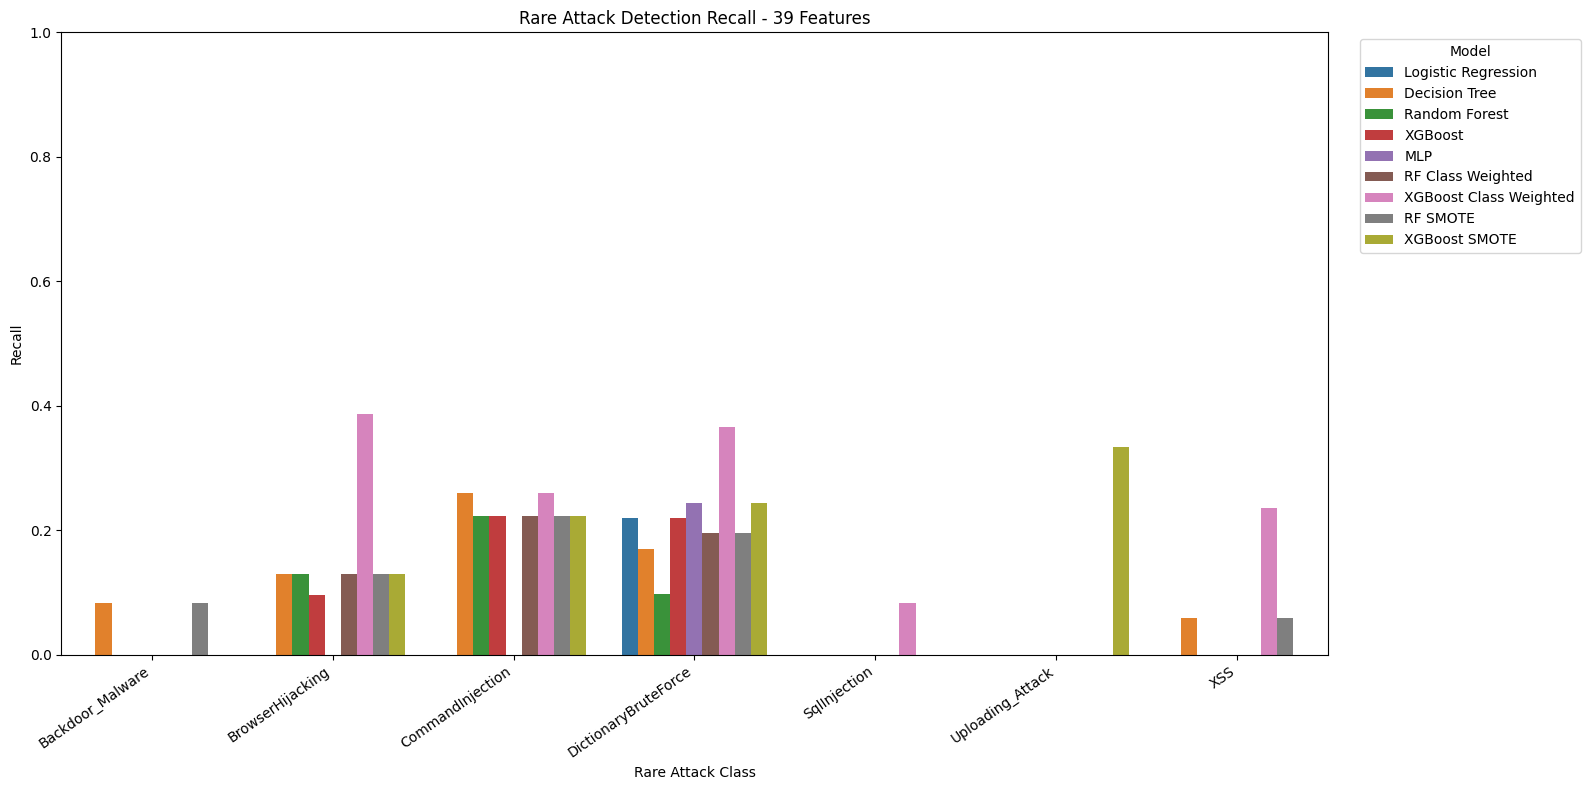

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns

rare_39 = rare_comparison_34[
    rare_comparison_34["Feature_Count"] == 39
].copy()

plt.figure(figsize=(16, 8))

sns.barplot(
    data=rare_39,
    x="Class",
    y="recall",
    hue="Model"
)

plt.title("Rare Attack Detection Recall - 39 Features")
plt.xlabel("Rare Attack Class")
plt.ylabel("Recall")
plt.xticks(rotation=35, ha="right")
plt.ylim(0, 1)
plt.legend(
    title="Model",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()

plt.savefig(
    results_path + "figures/rare_attack_recall_39_features.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

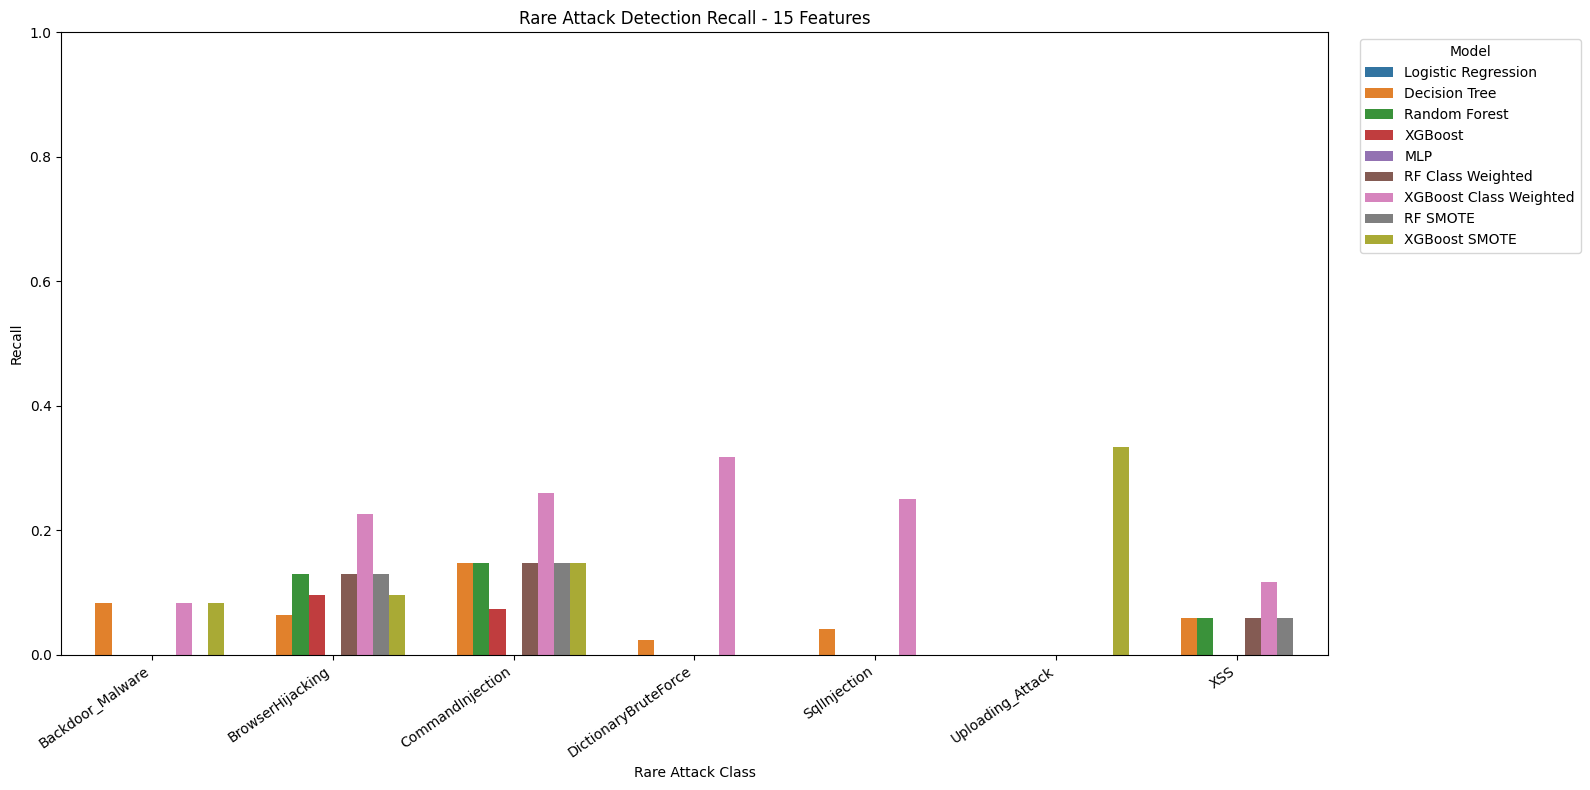

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns

rare_15 = rare_comparison_34[
    rare_comparison_34["Feature_Count"] == 15
].copy()

plt.figure(figsize=(16, 8))

sns.barplot(
    data=rare_15,
    x="Class",
    y="recall",
    hue="Model"
)

plt.title("Rare Attack Detection Recall - 15 Features")
plt.xlabel("Rare Attack Class")
plt.ylabel("Recall")
plt.xticks(rotation=35, ha="right")
plt.ylim(0, 1)
plt.legend(
    title="Model",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()

plt.savefig(
    results_path + "figures/rare_attack_recall_15_features.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [17]:
import os

results_path = "/content/drive/MyDrive/shared iot/results/"
figures_path = results_path + "figures/"

print("========== 34-CLASS RESULT FILES ==========")

for f in sorted(os.listdir(results_path)):
    if "34class" in f or "thirtyfour" in f or "rare_attack" in f or "best_rare" in f:
        print("✓", f)

print("\n========== FIGURES ==========")

for f in sorted(os.listdir(figures_path)):
    print("✓", f)

print("\nTotal figures:", len(os.listdir(figures_path)))

========== 34-CLASS RESULT FILES ==========
✓ all_rare_attack_recall_comparison_34class.csv
✓ best_rare_models_34class.csv
✓ rf_smote_34class_results.csv
✓ thirtyfour_class_all_per_class_reports.csv
✓ thirtyfour_class_balancing_reports.csv
✓ thirtyfour_class_master_results.csv
✓ xgb_smote_34class_results.csv
✓ xgboost_class_weighted_34class_results.csv

========== FIGURES ==========
✓ accuracy_comparison.png
✓ accuracy_comparison_8class_15.png
✓ accuracy_comparison_8class_39.png
✓ accuracy_comparison_final.png
✓ balancing_method_comparison_8class.png
✓ benign_recall_balancing_final.png
✓ confusion_matrices.png
✓ feature_count_vs_macro_f1.png
✓ feature_reduction_8class.png
✓ feature_reduction_final.png
✓ macro_f1_comparison.png
✓ macro_f1_comparison_8class_15.png
✓ macro_f1_comparison_8class_39.png
✓ macro_f1_comparison_final.png
✓ random_forest_confusion_matrices.png
✓ rare_attack_recall_15_features.png
✓ rare_attack_recall_39_features.png
✓ rare_class_recall_comparison.png

Total figu

In [18]:
import os

figures_path = results_path + "figures/"

for f in sorted(os.listdir(figures_path)):
    if f.endswith(".png"):
        size_kb = os.path.getsize(
            os.path.join(figures_path, f)
        ) / 1024

        print(f"{f}  |  {size_kb:.1f} KB")

accuracy_comparison.png  |  214.2 KB
accuracy_comparison_8class_15.png  |  127.4 KB
accuracy_comparison_8class_39.png  |  129.9 KB
accuracy_comparison_final.png  |  361.9 KB
balancing_method_comparison_8class.png  |  237.2 KB
benign_recall_balancing_final.png  |  190.1 KB
confusion_matrices.png  |  165.8 KB
feature_count_vs_macro_f1.png  |  161.4 KB
feature_reduction_8class.png  |  148.9 KB
feature_reduction_final.png  |  260.7 KB
macro_f1_comparison.png  |  199.4 KB
macro_f1_comparison_8class_15.png  |  124.5 KB
macro_f1_comparison_8class_39.png  |  127.6 KB
macro_f1_comparison_final.png  |  359.8 KB
random_forest_confusion_matrices.png  |  222.5 KB
rare_attack_recall_15_features.png  |  295.4 KB
rare_attack_recall_39_features.png  |  297.0 KB
rare_class_recall_comparison.png  |  186.6 KB


In [19]:
master_results_34 = pd.read_csv(
    saved_path + "thirtyfour_class_master_results.csv"
)

print("Columns:")
print(master_results_34.columns.tolist())

print("\nFirst rows:")
display(master_results_34.head(15))

print("\nData types:")
print(master_results_34.dtypes)

Columns:
['Model', 'Accuracy', 'Macro-F1']

First rows:


,Model,Accuracy,Macro-F1
0,XGBoost - 39 Features,0.813790,0.597394
1,Random Forest - 39 Features,0.798323,0.593963
2,Decision Tree - 39 Features,0.775661,0.560839
3,MLP - 39 Features,0.802705,0.554373
4,Random Forest - 15 Features,0.709989,0.534114
5,XGBoost - 15 Features,0.733104,0.526470
6,Logistic Regression - 39 Features,0.787978,0.522252
7,Decision Tree - 15 Features,0.691257,0.502103
8,MLP - 15 Features,0.718014,0.493450
9,Logistic Regression - 15 Features,0.691658,0.432060



Data types:
Model        object
Accuracy    float64
Macro-F1    float64
dtype: object


In [20]:
balancing_files_34 = [
    "random_forest_class_weighted_39_results.csv",
    "random_forest_class_weighted_15_results.csv",
    "xgboost_class_weighted_34class_results.csv",
    "rf_smote_34class_results.csv",
    "xgb_smote_34class_results.csv"
]

for filename in balancing_files_34:
    path = results_path + filename

    if os.path.exists(path):
        temp_df = pd.read_csv(path)
        print(f"\n========== {filename} ==========")
        print(temp_df.columns.tolist())
        display(temp_df.head())
    else:
        print(f"\nNot found in results folder: {filename}")


Not found in results folder: random_forest_class_weighted_39_results.csv

Not found in results folder: random_forest_class_weighted_15_results.csv

========== xgboost_class_weighted_34class_results.csv ==========
['Model', 'Feature_Count', 'Accuracy', 'Macro-F1']


,Model,Feature_Count,Accuracy,Macro-F1
0,XGBoost - Class Weighted,39,0.793585,0.576415
1,XGBoost - Class Weighted,15,0.710178,0.519558



========== rf_smote_34class_results.csv ==========
['Model', 'Feature_Count', 'Accuracy', 'Macro-F1']


,Model,Feature_Count,Accuracy,Macro-F1
0,Random Forest - SMOTE,39,0.797544,0.602181
1,Random Forest - SMOTE,15,0.710617,0.531707



========== xgb_smote_34class_results.csv ==========
['Model', 'Feature_Count', 'Accuracy', 'Macro-F1']


,Model,Feature_Count,Accuracy,Macro-F1
0,XGBoost - SMOTE,39,0.813496,0.598088
1,XGBoost - SMOTE,15,0.732817,0.533407


In [21]:
# Load confirmed results
original_34 = pd.read_csv(
    saved_path + "thirtyfour_class_master_results.csv"
)

xgb_weighted_34 = pd.read_csv(
    results_path + "xgboost_class_weighted_34class_results.csv"
)

rf_smote_34 = pd.read_csv(
    results_path + "rf_smote_34class_results.csv"
)

xgb_smote_34 = pd.read_csv(
    results_path + "xgb_smote_34class_results.csv"
)

# Keep only original Random Forest and XGBoost
original_balancing_34 = original_34[
    original_34["Model"].str.contains(
        "Random Forest|XGBoost", case=False
    )
].copy()

original_balancing_34["Method"] = "Original"

# Add balancing method labels
xgb_weighted_34["Method"] = "Class Weighted"
rf_smote_34["Method"] = "SMOTE"
xgb_smote_34["Method"] = "SMOTE"

# Combine all available results
balancing_comparison_34 = pd.concat(
    [
        original_balancing_34.rename(
            columns={"Model": "Model"}
        ),
        xgb_weighted_34,
        rf_smote_34,
        xgb_smote_34
    ],
    ignore_index=True
)

# Save combined comparison
balancing_comparison_34.to_csv(
    results_path + "balancing_comparison_34class.csv",
    index=False
)

display(balancing_comparison_34)

,Model,Accuracy,Macro-F1,Method,Feature_Count
0,XGBoost - 39 Features,0.813790,0.597394,Original,NaN
1,Random Forest - 39 Features,0.798323,0.593963,Original,NaN
2,Random Forest - 15 Features,0.709989,0.534114,Original,NaN
3,XGBoost - 15 Features,0.733104,0.526470,Original,NaN
4,XGBoost - Class Weighted,0.793585,0.576415,Class Weighted,39.0
5,XGBoost - Class Weighted,0.710178,0.519558,Class Weighted,15.0
6,Random Forest - SMOTE,0.797544,0.602181,SMOTE,39.0
7,Random Forest - SMOTE,0.710617,0.531707,SMOTE,15.0
8,XGBoost - SMOTE,0.813496,0.598088,SMOTE,39.0
9,XGBoost - SMOTE,0.732817,0.533407,SMOTE,15.0


In [23]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load original results
original_34 = pd.read_csv(
    saved_path + "thirtyfour_class_master_results.csv"
)

# Load class-weighted results
xgb_weighted_34 = pd.read_csv(
    results_path + "xgboost_class_weighted_34class_results.csv"
)

# Load SMOTE results
rf_smote_34 = pd.read_csv(
    results_path + "rf_smote_34class_results.csv"
)

xgb_smote_34 = pd.read_csv(
    results_path + "xgb_smote_34class_results.csv"
)

# Add the confirmed Random Forest class-weighted results
rf_weighted_34 = pd.DataFrame({
    "Model": [
        "Random Forest - Class Weighted",
        "Random Forest - Class Weighted"
    ],
    "Feature_Count": [39, 15],
    "Accuracy": [
        0.7970303763034607,
        0.7090222155055161
    ],
    "Macro-F1": [
        0.5941277666982488,
        0.5324131905789713
    ]
})

# Keep only original Random Forest and XGBoost results
original_balancing_34 = original_34[
    original_34["Model"].str.contains(
        "Random Forest|XGBoost",
        case=False
    )
].copy()

original_balancing_34["Method"] = "Original"

# Assign methods to the other results
rf_weighted_34["Method"] = "Class Weighted"
xgb_weighted_34["Method"] = "Class Weighted"

rf_smote_34["Method"] = "SMOTE"
xgb_smote_34["Method"] = "SMOTE"

# Combine everything
balancing_comparison_34 = pd.concat(
    [
        original_balancing_34,
        rf_weighted_34,
        xgb_weighted_34,
        rf_smote_34,
        xgb_smote_34
    ],
    ignore_index=True
)

# Save combined results
balancing_comparison_34.to_csv(
    results_path + "balancing_comparison_34class.csv",
    index=False
)

display(balancing_comparison_34)

,Model,Accuracy,Macro-F1,Method,Feature_Count
0,XGBoost - 39 Features,0.813790,0.597394,Original,NaN
1,Random Forest - 39 Features,0.798323,0.593963,Original,NaN
2,Random Forest - 15 Features,0.709989,0.534114,Original,NaN
3,XGBoost - 15 Features,0.733104,0.526470,Original,NaN
4,Random Forest - Class Weighted,0.797030,0.594128,Class Weighted,39.0
5,Random Forest - Class Weighted,0.709022,0.532413,Class Weighted,15.0
6,XGBoost - Class Weighted,0.793585,0.576415,Class Weighted,39.0
7,XGBoost - Class Weighted,0.710178,0.519558,Class Weighted,15.0
8,Random Forest - SMOTE,0.797544,0.602181,SMOTE,39.0
9,Random Forest - SMOTE,0.710617,0.531707,SMOTE,15.0


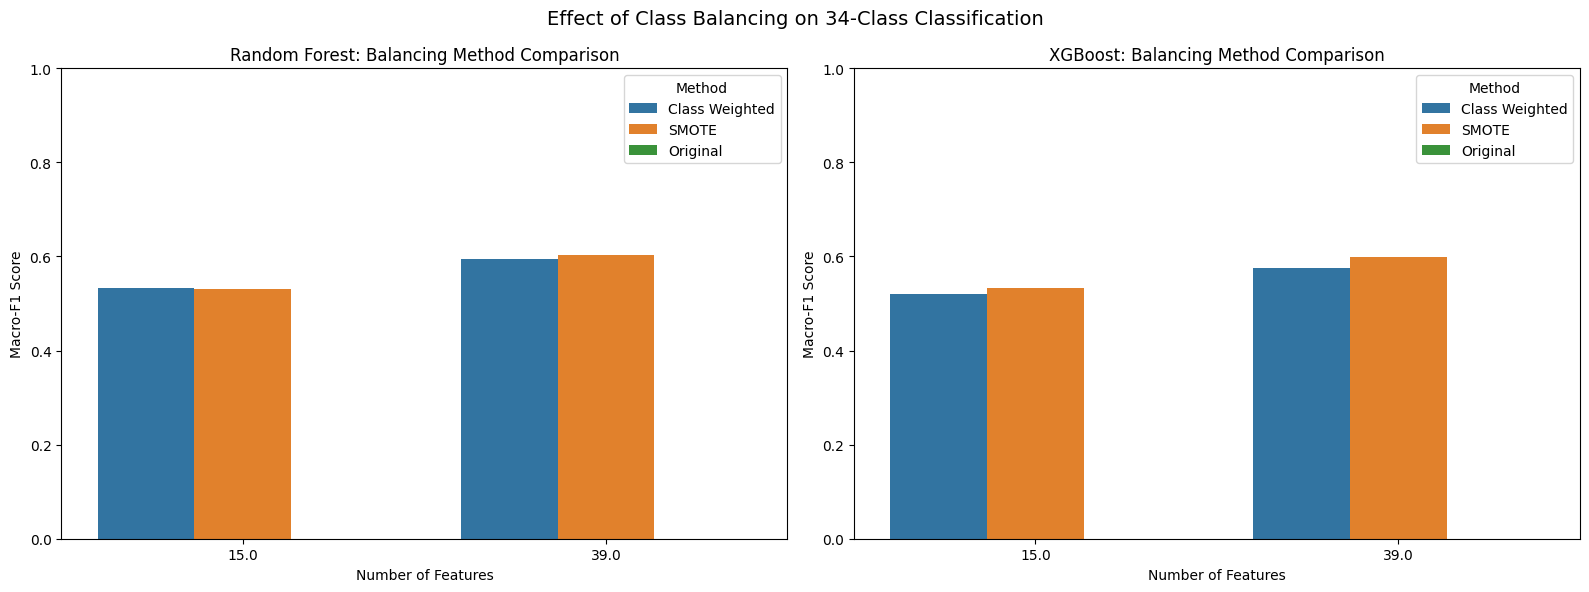

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

models = ["Random Forest", "XGBoost"]

for ax, model in zip(axes, models):

    model_data = balancing_comparison_34[
        balancing_comparison_34["Model"].str.contains(
            model,
            case=False
        )
    ].copy()

    sns.barplot(
        data=model_data,
        x="Feature_Count",
        y="Macro-F1",
        hue="Method",
        errorbar=None,
        ax=ax
    )

    ax.set_title(f"{model}: Balancing Method Comparison")
    ax.set_xlabel("Number of Features")
    ax.set_ylabel("Macro-F1 Score")
    ax.set_ylim(0, 1)
    ax.legend(title="Method")

plt.suptitle(
    "Effect of Class Balancing on 34-Class Classification",
    fontsize=14
)

plt.tight_layout()

plt.savefig(
    figures_path + "balancing_method_comparison_34class.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

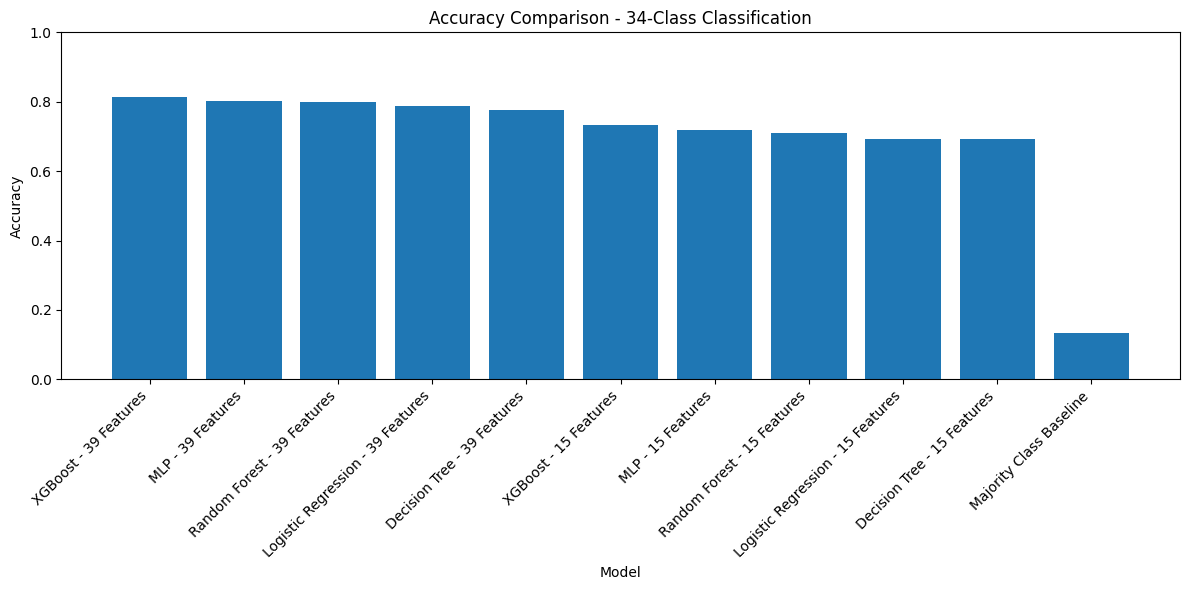

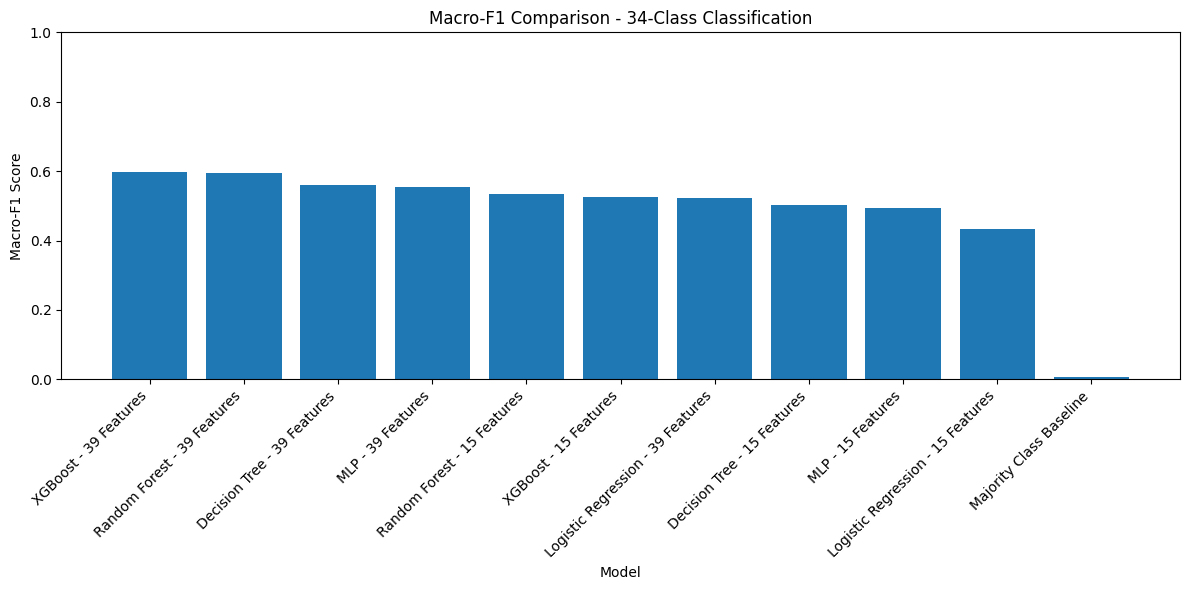

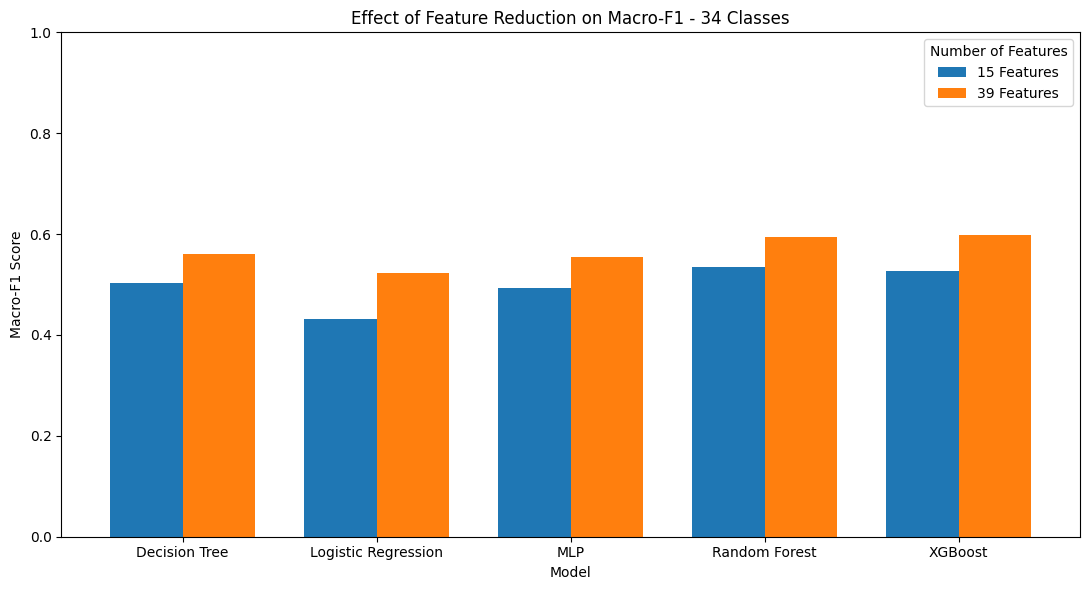


34-CLASS FIGURES GENERATED:
FOUND: accuracy_comparison_34class.png
FOUND: macro_f1_comparison_34class.png
FOUND: feature_reduction_34class.png
FOUND: rare_attack_recall_39_features.png
FOUND: rare_attack_recall_15_features.png
FOUND: balancing_method_comparison_34class.png


In [25]:

import pandas as pd
import matplotlib.pyplot as plt
import re
import os

# Load the 34-class master results
master_34 = pd.read_csv(
    saved_path + "thirtyfour_class_master_results.csv"
)

# -----------------------------------------
# FIGURE 1: ACCURACY COMPARISON
# -----------------------------------------

accuracy_data = master_34.sort_values(
    by="Accuracy", ascending=False
)

plt.figure(figsize=(12, 6))

plt.bar(
    accuracy_data["Model"],
    accuracy_data["Accuracy"]
)

plt.title("Accuracy Comparison - 34-Class Classification")
plt.xlabel("Model")
plt.ylabel("Accuracy")
plt.ylim(0, 1)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()

plt.savefig(
    figures_path + "accuracy_comparison_34class.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# -----------------------------------------
# FIGURE 2: MACRO-F1 COMPARISON
# -----------------------------------------

macro_f1_data = master_34.sort_values(
    by="Macro-F1", ascending=False
)

plt.figure(figsize=(12, 6))

plt.bar(
    macro_f1_data["Model"],
    macro_f1_data["Macro-F1"]
)

plt.title("Macro-F1 Comparison - 34-Class Classification")
plt.xlabel("Model")
plt.ylabel("Macro-F1 Score")
plt.ylim(0, 1)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()

plt.savefig(
    figures_path + "macro_f1_comparison_34class.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# -----------------------------------------
# FIGURE 3: FEATURE REDUCTION COMPARISON
# -----------------------------------------

feature_data = master_34.copy()

# Extract feature count from model names
feature_data["Feature_Count"] = feature_data["Model"].str.extract(
    r"(15|39)\s*Features",
    flags=re.IGNORECASE
)

feature_data["Feature_Count"] = pd.to_numeric(
    feature_data["Feature_Count"],
    errors="coerce"
)

# Remove feature count from model names
feature_data["Base_Model"] = feature_data["Model"].str.replace(
    r"\s*-\s*(15|39)\s*Features",
    "",
    regex=True,
    flags=re.IGNORECASE
).str.strip()

# Keep models that have both 15 and 39 feature results
feature_data = feature_data.dropna(
    subset=["Feature_Count"]
)

macro_pivot = feature_data.pivot(
    index="Base_Model",
    columns="Feature_Count",
    values="Macro-F1"
)

macro_pivot = macro_pivot.dropna(
    subset=[15, 39]
)

# Plot grouped bars
ax = macro_pivot[[15, 39]].plot(
    kind="bar",
    figsize=(11, 6),
    width=0.75
)

ax.set_title("Effect of Feature Reduction on Macro-F1 - 34 Classes")
ax.set_xlabel("Model")
ax.set_ylabel("Macro-F1 Score")
ax.set_ylim(0, 1)
ax.set_xticklabels(
    ax.get_xticklabels(),
    rotation=0
)
ax.legend(
    title="Number of Features",
    labels=["15 Features", "39 Features"]
)

plt.tight_layout()

plt.savefig(
    figures_path + "feature_reduction_34class.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# -----------------------------------------
# VERIFY SAVED FIGURES
# -----------------------------------------

print("\n34-CLASS FIGURES GENERATED:")

figure_files = [
    "accuracy_comparison_34class.png",
    "macro_f1_comparison_34class.png",
    "feature_reduction_34class.png",
    "rare_attack_recall_39_features.png",
    "rare_attack_recall_15_features.png",
    "balancing_method_comparison_34class.png"
]

for filename in figure_files:
    filepath = figures_path + filename

    if os.path.exists(filepath):
        print("FOUND:", filename)
    else:
        print("MISSING:", filename)


In [26]:

import os

folders_to_check = {
    "34-Class Saved Data": saved_path,
    "Results": results_path,
    "Figures": figures_path
}

for folder_name, folder_path in folders_to_check.items():

    print("\n" + "=" * 65)
    print(folder_name)
    print("Path:", folder_path)
    print("=" * 65)

    if os.path.exists(folder_path):
        files = sorted(os.listdir(folder_path))

        for filename in files:
            full_path = os.path.join(folder_path, filename)

            if os.path.isfile(full_path):
                size_mb = os.path.getsize(full_path) / (1024 * 1024)
                print(f"{filename}  ({size_mb:.2f} MB)")
            else:
                print(f"{filename}/")

        print(f"\nTotal items: {len(files)}")

    else:
        print("FOLDER NOT FOUND")



34-Class Saved Data
Path: /content/drive/MyDrive/shared iot/34class_saved/
all_rare_attack_recall_comparison_34class.csv  (0.01 MB)
balancing/
baseline_34class_results.csv  (0.00 MB)
decision_tree_15_per_class_report.csv  (0.00 MB)
decision_tree_34class_results.csv  (0.00 MB)
decision_tree_39_per_class_report.csv  (0.00 MB)
decision_tree_predictions.joblib  (2.02 MB)
logistic_regression_15_per_class_report.csv  (0.00 MB)
logistic_regression_34class_results.csv  (0.00 MB)
logistic_regression_39_per_class_report.csv  (0.00 MB)
logistic_regression_predictions.joblib  (2.02 MB)
mlp_15_per_class_report.csv  (0.00 MB)
mlp_15_predictions.joblib  (1.01 MB)
mlp_15_results.csv  (0.00 MB)
mlp_39_per_class_report.csv  (0.00 MB)
mlp_39_predictions.joblib  (1.01 MB)
mlp_39_results.csv  (0.00 MB)
random_forest_15_per_class_report.csv  (0.00 MB)
random_forest_15_predictions.joblib  (1.01 MB)
random_forest_15_results.csv  (0.00 MB)
random_forest_34class_results.csv  (0.00 MB)
random_forest_39_per_clas